## PRCP-1020 -- House Price Prediction (Advanced)
#### Goal: Predict house sale prices from 79 property features(Ames, Iowa) 
#### Metric: RMSE on log(SalePrice), 5-fold cross-validation + 20% holdout.

#### Contents:

1. Setup & Data Load
2. Task 1 - Data Analysis Report
3. Task 2a - Predictive model
4. Task 2b - Feature-Price Relationships
5. Task 3 - Buyer Recommendations
6. Model Comparison Report
7. Challenges Report

## 1. Setup and Data Load

### 1.1 Safely Load The DataSet

In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)

DATA_PATH = "../data/data.csv"

df = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[""])   #1

print(df.shape)
df.head()


#1
# in this dataset there are values as NA, None. they can be unknown or show absense
# when we load file using csv pandas convert this value as "NaN". and we lose the data it gets corrupted.
# ex. house has no pool and unknown are different meanings if we try to fix it using
# imputing the data may show falsy generated pools on houses containing no pools.(the data got corrupted)

# keep_default_na=False disables pandas default token list ("NA","None", "null"...)
# those string now loads as ordinary category value
# na_values=[""] - only genuinely empty cell now count as missing "NaN"

# YOU CONTROL THE MEANING OF MISSINGNESS PER COLUMN INSTEAD OF PANDAS GUESSING.

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65,8450,Pave,NA,Reg,Lvl,AllPub,...,0,NA,NA,NA,0,2,2008,WD,Normal,208500
1,2,20,RL,80,9600,Pave,NA,Reg,Lvl,AllPub,...,0,NA,NA,NA,0,5,2007,WD,Normal,181500
2,3,60,RL,68,11250,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,9,2008,WD,Normal,223500
3,4,70,RL,60,9550,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84,14260,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,12,2008,WD,Normal,250000


In [2]:
# PROOF : the code preserves the category/missing distinction

print("MasVnrType value counts:")
print(df["MasVnrType"].value_counts(dropna=False))

print("\nAlley value counts:")
print(df["Alley"].value_counts(dropna=False))

MasVnrType value counts:
MasVnrType
None       864
BrkFace    445
Stone      128
BrkCmn      15
NA           8
Name: count, dtype: int64

Alley value counts:
Alley
NA      1369
Grvl      50
Pave      41
Name: count, dtype: int64


### 1.2 Data Type Audit

In [3]:
df.dtypes.value_counts()

str      46
int64    35
Name: count, dtype: int64

In [4]:
# Numeric columns per the data description ( storage should be int/float)
EXPECTED_NUMERIC = [
    "Id", "MSSubClass", "LotFrontage", "LotArea", "OverallQual", "OverallCond",
    "YearBuilt", "YearRemodAdd", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2",
    "BsmtUnfSF", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "LowQualFinSF",
    "GrLivArea", "BsmtFullBath", "BsmtHalfBath", "FullBath", "HalfBath",
    "BedroomAbvGr", "KitchenAbvGr", "TotRmsAbvGrd", "Fireplaces",
    "GarageYrBlt", "GarageCars", "GarageArea", "WoodDeckSF", "OpenPorchSF",
    "EnclosedPorch", "3SsnPorch", "ScreenPorch", "PoolArea", "MiscVal",
    "MoSold", "YrSold", "SalePrice",
]  # 38 columns -> the other 43 should be text

In [5]:
stored_numeric = set(df.select_dtypes(include="number").columns)
expected_numeric = set(EXPECTED_NUMERIC)

broken = expected_numeric - stored_numeric      # should be numeric, but aren't
extra = stored_numeric - expected_numeric       # numeric but undocumented

print("Broken (documented numeric, stored as text):", sorted(broken))
print("Extra (numeric but not documented as such):", sorted(extra))

Broken (documented numeric, stored as text): ['GarageYrBlt', 'LotFrontage', 'MasVnrArea']
Extra (numeric but not documented as such): []


### 1.3 Diagnose the 3 broken columns

In [6]:
# Since we know there are 3 columns which have wrong dtype we need to convert them in 
# numeric columns 
# we first need to decide how can we safely convert them without changing the meaning of data
# in following code we diagnose if the NA value is actulally showing that the feature is missing 
# or feature is present and only value is missing
# we do this with the help of other related feature by understanding the feature


# GarageYrBlt: the "NA" houses - do they even have garages?
print(df.loc[df["GarageYrBlt"] == "NA", "GarageType"].value_counts())

#MasVnrArea: the "NA" houses -- what's their MasVnrType?
print(df.loc[df["MasVnrArea"] == "NA", "MasVnrType"].value_counts())

# LotFrontage: how many, and is there structural pattern>
print("LotFrontage 'NA' count:", (df["LotFrontage"] == "NA").sum())
print(df.loc[df["LotFrontage"] == "NA", "Neighborhood"].value_counts().head())

GarageType
NA    81
Name: count, dtype: int64
MasVnrType
NA    8
Name: count, dtype: int64
LotFrontage 'NA' count: 259
Neighborhood
NAmes      39
Gilbert    30
NWAmes     28
Sawyer     26
CollgCr    24
Name: count, dtype: int64


### 1.4 Repair and Verify

In [7]:
# FIX
for col in sorted(broken):
    df[col] = pd.to_numeric(df[col], errors="coerce")    #"NA" -> NaN, numbers stay

In [8]:
stored_numeric = set(df.select_dtypes(include="number").columns)
print("Still broken:", sorted(expected_numeric - stored_numeric))
print("Numeric columns now:", len(stored_numeric))
print(df.dtypes.value_counts())
missing = df.isna().sum()
print(missing[missing > 0])

Still broken: []
Numeric columns now: 38
str        43
int64      35
float64     3
Name: count, dtype: int64
LotFrontage    259
MasVnrArea       8
GarageYrBlt     81
dtype: int64


### Findings - data type audit

1. all columns compared against their documented types. total 38 - found 35.
2. located this 3 columns by comparing to documented numeric list.
3. reason: file encode all blank values as NA strings so they were stored as text
4. Diagnosis:
   GarageYrBlt "NA" = absence (those houses have no garage)
   LotFrontage "NA" = genuine unknown (259 houses, scattered - no pattern)
   MasVnrArea "NA" = genuine unknown (8 houses, same rows as MasVnrType "NA")
5. Repair: pd.to_numeric(errors="coerce")  - only "NA" becomes NaN.
6. Verified: 38 numeric columns = 35 int64 + 3 float64
7. Mismatch in column names from documentation
    document say "Bedroom", file says "BedroomAbvGr"
    document say "kitchen", file says "KitchenABvGr"

In [9]:
print("\nColumn names check (spec says 'Bedroom' — reality says...):")
print([c for c in df.columns if "Bedroom" in c or "Kitchen" in c])


Column names check (spec says 'Bedroom' — reality says...):
['BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual']


### the inventory = finding all NaN, NA and None values across whole table

In [10]:
inventory = pd.DataFrame({
    "nan": df.isna().sum(),
    "NA_str": (df == "NA").sum(),
    "None_str": (df == "None").sum(),
})

inventory["total"] = inventory.sum(axis=1)

inventory = inventory[inventory["total"] > 0].sort_values("total", ascending=False)   # this just hide the columns which contains 0 of this 3 types
inventory

,nan,NA_str,None_str,total
PoolQC,0,1453,0,1453
MiscFeature,0,1406,0,1406
Alley,0,1369,0,1369
Fence,0,1179,0,1179
MasVnrType,0,8,864,872
FireplaceQu,0,690,0,690
LotFrontage,259,0,0,259
GarageType,0,81,0,81
GarageYrBlt,81,0,0,81
GarageFinish,0,81,0,81


#### observation:
1. Only 19 columns contain Nan, NA or None values. remaining 62 columns are clean
2. the column named as MasVnrType contain "none"(864) times is documented category
   so "None" means the house does not have this feature
   the remaining 8 "NA" means the values are missing.
3. the basement related columns total 5 columns have some mismatch
   if the house contain no basement all column values should match
4. same with Garage related 5 columns

#### Cross checking with documentation for NA values
In the given dataset documentation 14 columns document "NA" = absence
MasVnrType and electrical do not document "NA".

if "NA" means the house lacks the feature, the related count/area column must be zero
if "NA" means missing value the related features must have a value
we can use this logic to differentiate the meaning of "NA"

In [11]:
# 1. to find value meaning in FireplaceQu column (690 "NA")
# compare it to fireplaces column (if house has no fireplace the fireplaceQu should not exist)
print(df.loc[df["FireplaceQu"] == "NA", "Fireplaces"].value_counts())
print()

# 2. if garage does not exist then garagetype, garagecars, garagearea should not exist
g = df["GarageType"] == "NA"
print(df.loc[g, "GarageCars"].value_counts())
print(df.loc[g, "GarageArea"].unique())
print()

# 3. Basement on BsmtQual == "NA" houses
print(df.loc[df["BsmtQual"] == "NA", "TotalBsmtSF"].value_counts())
print()

# 4.Reverse: houses with pool - do all have PoolQC?
print(df.loc[df["PoolArea"] > 0, ["PoolArea", "PoolQC"]])
print()

# 5. Reverse: houses With fireplaces - any FireplaceQu == ""NA"?
print((df.loc[df["Fireplaces"] > 0, "FireplaceQu"] == "NA").sum())
print()

# 6. since there is mismatch is basement related column 'NA' value 

basement_cols = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
print((df[basement_cols] == "NA").sum())

no_basement = df["TotalBsmtSF"] == 0
for col in basement_cols:
    has_basement_but_NA = (df[col] == "NA") & ~no_basement
    no_basement_but_val = (df[col] != "NA") & no_basement
    if has_basement_but_NA.any():
        print(f"\n{col}: Has basement but column is 'NA':")
        print(df.loc[has_basement_but_NA, ["Id", col, "TotalBsmtSF", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF"]])
    if no_basement_but_val.any():
        print(f"\n{col}: NO basement but column has a value")
print()

# 7. for column MasVnrType we check related column MasVnrArea value
print(df.loc[df["MasVnrType"] == "NA", ["MasVnrType", "MasVnrArea"]])
print()
#    for column Electrical we check related column utilities, yearbuilt
print(df.loc[df["Electrical"] == "NA", ["Id", "Electrical", "Utilities", "YearBuilt"]])

Fireplaces
0    690
Name: count, dtype: int64

GarageCars
0    81
Name: count, dtype: int64
[0]

TotalBsmtSF
0    37
Name: count, dtype: int64

      PoolArea PoolQC
197        512     Ex
810        648     Fa
1170       576     Gd
1182       555     Ex
1298       480     Gd
1386       519     Fa
1423       738     Gd

0

BsmtQual        37
BsmtCond        37
BsmtExposure    38
BsmtFinType1    37
BsmtFinType2    38
dtype: int64

BsmtExposure: Has basement but column is 'NA':
      Id BsmtExposure  TotalBsmtSF  BsmtFinSF1  BsmtFinSF2  BsmtUnfSF
948  949           NA          936           0           0        936

BsmtFinType2: Has basement but column is 'NA':
      Id BsmtFinType2  TotalBsmtSF  BsmtFinSF1  BsmtFinSF2  BsmtUnfSF
332  333           NA         3206        1124         479       1603

     MasVnrType  MasVnrArea
234          NA         NaN
529          NA         NaN
650          NA         NaN
936          NA         NaN
973          NA         NaN
977          NA        

#### Observations: 
1. FireplaceQu "NA" = the feature does not exist in that house
    690 FireplaceQu "NA" values have fireplaces value as 0

2. Garage related columns "NA" values = the feature does not exist
    GarageArea shows value 0 for all this rows
    so GarageType, GarageYrBlt, GarageFinish, GarageQual, GarageCond
    this five columns "NA" values = does not exist for that house

3. BsmtQual, BsmtCond, BsmtFinType1	 = the feature does not exist
    since TotalBsmtSF = 0 for this rows

4. PoolQC "NA" meaning = the feature does not exist
   only 7 houses have pool in this dataset and each have their poolQc value
    so remaining must be because pool does not exist

5. each house having fireplace has corresponding fireplaceQu value.

6. No basement but has value finds nothing -
    all 37 zero- sf houses are consistent "NA" everywhere
    1. id 949 column BsmtExposure = "NA"
       this house has real basement whose exposure is unknown = missing value
       need to impute
    2. id 333 column BsmtFinType2 = "NA"
        this house has real basement with BsmtFinSF2 = 479  but its quality grade
        is unknown = missing value need to impute
       (BsmtFinSF2 = 479 says the value of BsmtFinType2 must exist)

7. for MasVnrType column all "NA" values have corresponding Nan value in
    MasVnrArea Column
    we conclude that its Genuinely missing data

    For Electrical column a single house has "NA" value
    the house has AllPub utilities and is modern
    we conclude the data is missing value.

8. MiscFeature, Alley, Fence This 3 columns were judged on basis of provided            documentation since no related column exist for cross refrence

| Column | Form | Count | Class | action |
|---|---|---|---|---|
| PoolQC, MiscFeature, Alley, Fence, FireplaceQu | "NA" | 1453, 1406, 1369, 1179, 690 | Absence | fill "None" |
| GarageType, GarageFinish, GarageQual, GarageCond | "NA" | 81 each | Absence | fill "None" |
| GarageYrBlt | NaN | 81 | Absence (no garage) | fill YearBuilt + HasGarage flag |
| BsmtQual, BsmtCond, BsmtFinType1 | "NA" | 37 each | Absence | fill "None" |
| BsmtExposure | "NA" | 38 | 37 absence + **1 genuine** (Id 949) | fill "None" for 37; impute mode for 1 |
| BsmtFinType2 | "NA" | 38 | 37 absence + **1 genuine** (Id 333) | fill "None" for 37; impute mode (SF2>0 population) for 1 |
| MasVnrType | "None" | 864 | **Valid category — not missing** | nothing |
| MasVnrType | "NA" | 8 | Genuine missing | fill "None" (likeliest truth, 8 rows) |
| MasVnrArea | NaN | 8 | Genuine missing | fill 0 |
| LotFrontage | NaN | 259 | Genuine missing | impute median (inside pipeline) |
| Electrical | "NA" | 1 | Genuine missing | fill mode "SBrkr" |



#### Visual EDA

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

### Categorize the columns

In [13]:
TARGET = "SalePrice"
ID = "Id"

CONTINUOUS = [  # measured quantities — any value in a range
    "LotFrontage", "LotArea", "MasVnrArea",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "1stFlrSF", "2ndFlrSF", "LowQualFinSF", "GrLivArea",
    "GarageArea", "WoodDeckSF", "OpenPorchSF", "EnclosedPorch",
    "3SsnPorch", "ScreenPorch", "PoolArea", "MiscVal",
]  # 19

DISCRETE = [    # counted things — small whole numbers
    "BsmtFullBath", "BsmtHalfBath", "FullBath", "HalfBath",
    "BedroomAbvGr", "KitchenAbvGr", "TotRmsAbvGrd", "Fireplaces", "GarageCars",
]  # 9

TEMPORAL = [    # calendar values — engineered in Phase 2, not used raw
    "YearBuilt", "YearRemodAdd", "GarageYrBlt", "YrSold", "MoSold",
]  # 5

ORDINAL = [     # ordered rating scales — Ex > Gd > TA > Fa > Po etc.
    "OverallQual", "OverallCond", "LotShape", "Utilities", "LandSlope",
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "HeatingQC", "KitchenQual", "Functional",
    "FireplaceQu", "GarageFinish", "GarageQual", "GarageCond",
    "PavedDrive", "PoolQC", "Fence", "CentralAir",
]  # 23

NOMINAL = [     # labels, no order
    "MSSubClass", "MSZoning", "Street", "Alley", "LandContour", "LotConfig",
    "Neighborhood", "Condition1", "Condition2", "BldgType", "HouseStyle",
    "RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd", "MasVnrType",
    "Foundation", "Heating", "Electrical", "GarageType", "MiscFeature",
    "SaleType", "SaleCondition",
]  # 23

# Every column accounted for, exactly once — the completeness guarantee
assert set(CONTINUOUS + DISCRETE + TEMPORAL + ORDINAL + NOMINAL + [TARGET, ID]) == set(df.columns)
print("All 81 columns categorized ✔")

All 81 columns categorized ✔


#### Since SalePrice is a TARGET column we understand it first

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Skewness = 1.88


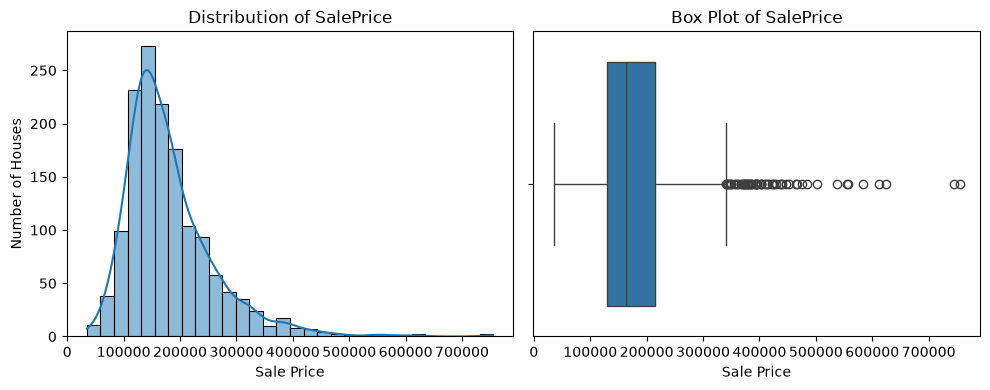

In [14]:
print(df['SalePrice'].describe())

# then we plot it to see distribution
print()
print(f"Skewness = {df['SalePrice'].skew():.2f}")

# Create a figure with 1 row and 2 columns of subplots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Plot 1: Histogram (Left Subplot)
sns.histplot(
    data=df,
    x="SalePrice",
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of SalePrice")
axes[0].set_xlabel("Sale Price")
axes[0].set_ylabel("Number of Houses")

# Plot 2: Box Plot (Right Subplot)
sns.boxplot(
    data=df,
    x="SalePrice",
    ax=axes[1]
)
axes[1].set_title("Box Plot of SalePrice")
axes[1].set_xlabel("Sale Price")

# Adjust spacing between subplots
plt.tight_layout()
plt.show()

#### Observation: 
    The SalePrice column is strongly right-skewed. (Skewness = 1.88)
    Most properties are concentrated towards lower to middle price range.
    Expensive properties create a long tail.
    The middle 50% of properties have sale prices between $129,975 and $214,000.
#### Conclusion:
    1. Since house prices can be expensive, some expensive house prices can dominate    
        squared error which will affect model performance.
    2. Need to use Log to make it evenly distributed.

#### which numerical features matters most


Top 10 columns having highest corerlation with SalePrice
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64
Top 5 columns having highest negative corerlation with SalePrice
KitchenAbvGr    -0.135907
EnclosedPorch   -0.128578
MSSubClass      -0.084284
OverallCond     -0.077856
YrSold          -0.028923
Name: SalePrice, dtype: float64


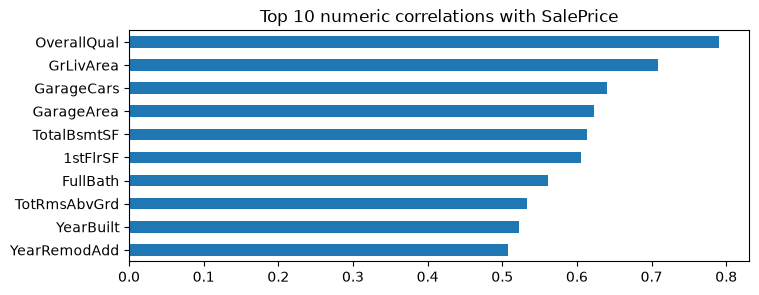

In [15]:
num_corr = df.select_dtypes(include="number").drop(columns=["Id"]).corr()

corr_with_price = num_corr["SalePrice"].drop("SalePrice")

# Ranked by STRENGTH (absolute value) — the correct way
top10 = corr_with_price.abs().sort_values(ascending=False).head(10)
print("Top 10 columns having highest corerlation with SalePrice")
print(corr_with_price.abs().sort_values(ascending=False).head(10))

# The most NEGATIVE relationships — what head(10) was hiding
print("Top 5 columns having highest negative corerlation with SalePrice")
print(corr_with_price.sort_values().head(5))

plt.figure(figsize=(8, 3))
top10.sort_values().plot(kind="barh")
plt.title("Top 10 numeric correlations with SalePrice")
plt.show()

#### Observation: 
    The above numeric columns have highest positive corelation with SalePrice column
    Negative corelation with SalePrice is weak.

#### The Categorical Map: 
    We use ANOVA F- statistic to determine which text column have stronger relation to 
    SalePrice

In [16]:
from scipy.stats import f_oneway

def category_f_score(frame, col, target='SalePrice'):
    """ANOVA F of target across col's categories.
    Singleton levels (<2 houses) excluded - no meaningful group mean."""
    groups = [np.log1p(g) for _, g in frame.groupby(col)[target] if len(g) >= 2]
    if len(groups) < 2:        #only one real category left
        return np.nan          # no comparison possible - variance `zero
    return f_oneway(*groups).statistic


cat_scores = pd.Series({col: category_f_score(df, col) for col in ORDINAL + NOMINAL})
cat_scores = cat_scores.sort_values(ascending=False)

print("TOP - strongest association with price:")
print(cat_scores.head(15))
print("\nBOTTOM - weakest (and NaN = no comparision possible):")
print(cat_scores.tail(8))

TOP - strongest association with price:
ExterQual       415.304259
KitchenQual     393.320922
OverallQual     332.166960
BsmtQual        300.392915
GarageFinish    298.769591
CentralAir      205.666008
HeatingQC       146.610039
FireplaceQu     131.198588
Foundation      126.806779
GarageType      121.796238
MasVnrType       87.834627
Neighborhood     79.520526
MSZoning         77.607607
PavedDrive       74.897900
BsmtFinType1     71.381818
dtype: float64

BOTTOM - weakest (and NaN = no comparision possible):
Condition1     8.037521
Functional     6.997305
Street         4.814434
MiscFeature    4.482666
PoolQC         3.985148
Condition2     3.631649
LandSlope      1.083050
Utilities           NaN
dtype: float64


#### Observations:
    ExterQual | KitchenQual | OverallQual | BsmtQual | GarageFinish 
    This are the top categorical columns who seprate price most
    Quality family + Neighborhood + OverallQual dominate
    Utilities = NaN (single category)

#### F-score penalizes many-category columns: η² measures variance share fairly regardless of category count.

In [17]:
def category_eta_sq(frame, col, target="SalePrice"):
    """Share of log-price variance explained by col's categories.
    Fair across different numbers of categories — unlike raw F."""
    groups = [np.log1p(g) for _, g in frame.groupby(col)[target] if len(g) >= 2]
    if len(groups) < 2:
        return np.nan
    all_vals = np.concatenate(groups)
    grand_mean = all_vals.mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
    ss_total = ((all_vals - grand_mean) ** 2).sum()
    return ss_between / ss_total

eta = pd.Series({col: category_eta_sq(df, col) for col in ORDINAL + NOMINAL})
comparison = pd.DataFrame({"F": cat_scores, "eta_sq": eta}).sort_values("eta_sq", ascending=False)
print(comparison.head(12).round(3))

                    F  eta_sq
OverallQual   332.167   0.673
Neighborhood   79.521   0.571
ExterQual     415.304   0.461
BsmtQual      300.393   0.452
KitchenQual   393.321   0.448
GarageFinish  298.770   0.381
GarageType    121.796   0.335
MSSubClass     50.866   0.330
FireplaceQu   131.199   0.311
Foundation    126.807   0.304
HeatingQC     146.610   0.232
BsmtFinType1   71.382   0.228


#### Observations:
    the ranking has changed after considering multiple categorys 
    Neighborhood shows more association with SalePrice

#### Plotting size columns

        Id  GrLivArea  SalePrice  OverallQual SaleCondition
523    524       4676     184750           10       Partial
691    692       4316     755000           10        Normal
1182  1183       4476     745000           10       Abnorml
1298  1299       5642     160000           10       Partial


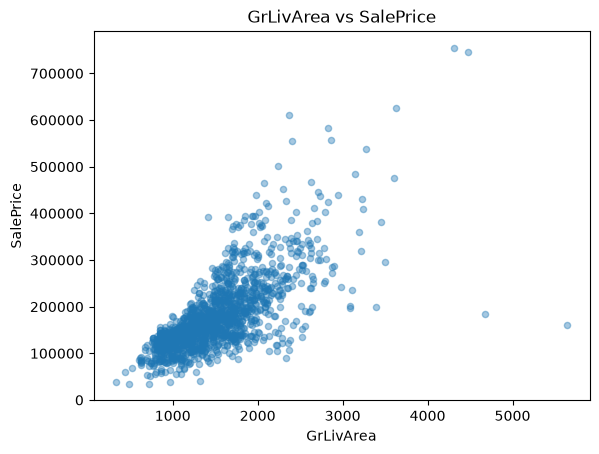

In [18]:
df.plot.scatter(x="GrLivArea", y="SalePrice", alpha=0.4, title="GrLivArea vs SalePrice")
print(df.loc[df["GrLivArea"] > 4000, ["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition"]])


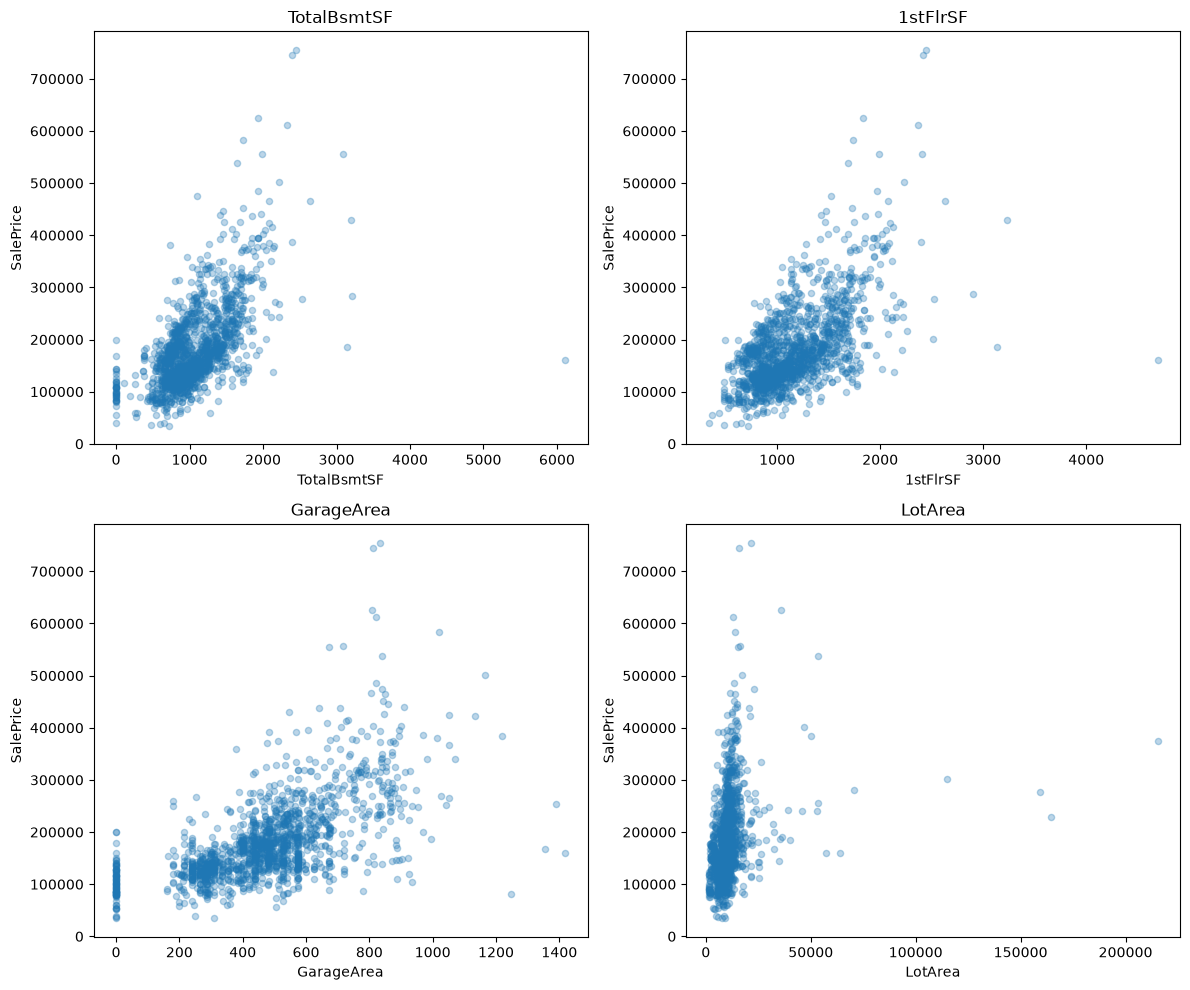

In [19]:
import matplotlib.pyplot as plt

cols = ["TotalBsmtSF", "1stFlrSF", "GarageArea", "LotArea"]

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Flatten 2D axes array (2, 2) into a 1D array (4,) for easier iteration
axes = axes.flatten()

# Plot each column on its corresponding subplot axis
for i, col in enumerate(cols):
    df.plot.scatter(
        x=col,
        y="SalePrice",
        alpha=0.3,
        title=col,
        ax=axes[i]
    )

# Adjust layout to prevent overlapping labels
plt.tight_layout()
plt.show()

#### Observations:
    ALL Five charts about size show same story
    AS size increases the price also increases
    GrLivArea has the strongest corelation with SalePrice
    while LotArea has weak relationship and is noisy.

In [20]:
# now check the extreme houses:
big = df[df['GrLivArea'] > 4000]
print(big[['Id', 'GrLivArea', 'SalePrice', 'OverallQual', 'YearBuilt', 'SaleCondition']])

        Id  GrLivArea  SalePrice  OverallQual  YearBuilt SaleCondition
523    524       4676     184750           10       2007       Partial
691    692       4316     755000           10       1994        Normal
1182  1183       4476     745000           10       1996       Abnorml
1298  1299       5642     160000           10       2008       Partial


we caught 4 extreme values 2 of them are plausible but other 2 contradict. both values for each column GrLivArea and Saleprice values are within that columns acceptable range but combined they show a different picture 

id 524 and id 1299 have big square footage but low price. We conclude their saleprice does not reflect market value and it may mislead the model.

#### Plotting Quality columns

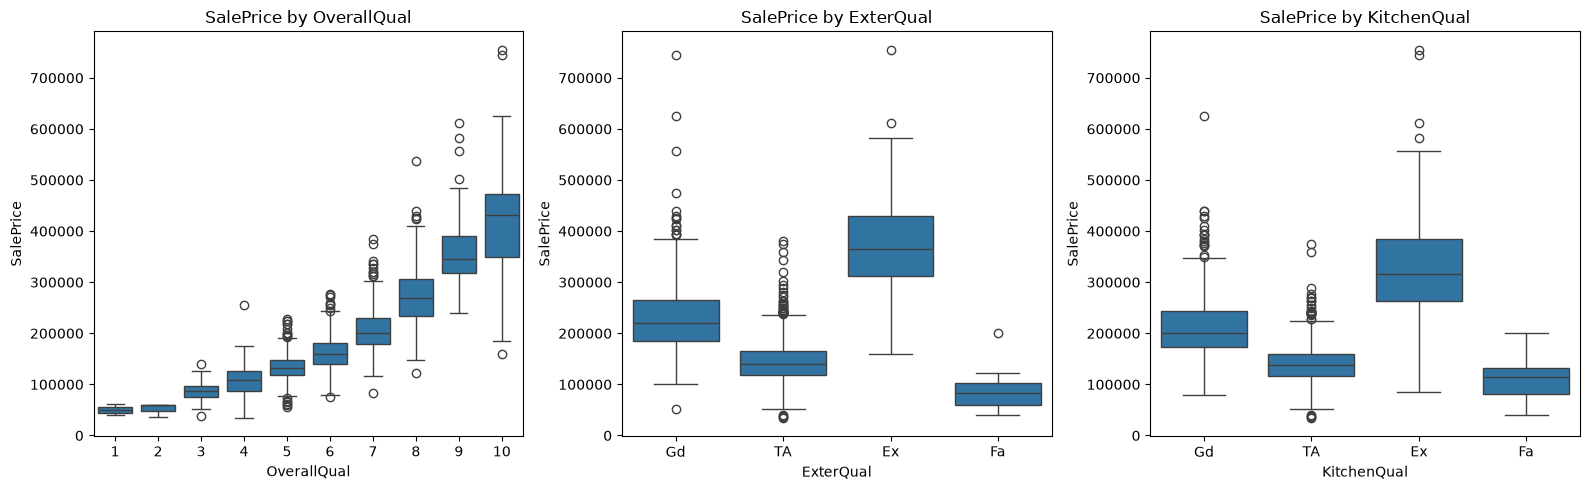

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["OverallQual", "ExterQual", "KitchenQual"]

# Create 1 row with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(cols):
    sns.boxplot(
        data=df,
        x=col,
        y="SalePrice",
        ax=axes[i]
    )
    axes[i].set_title(f"SalePrice by {col}")

plt.tight_layout()
plt.show()

#### Observations:
    Quality is one of the strongest and most consistent factors associated with 
    SalePrice in this dataset.
    Fa = Fair -> TA = Typical/Average -> Gd = Good -> Ex = Excellent
    all three plots show same progression quality increase assciated with price increase

#### Location:


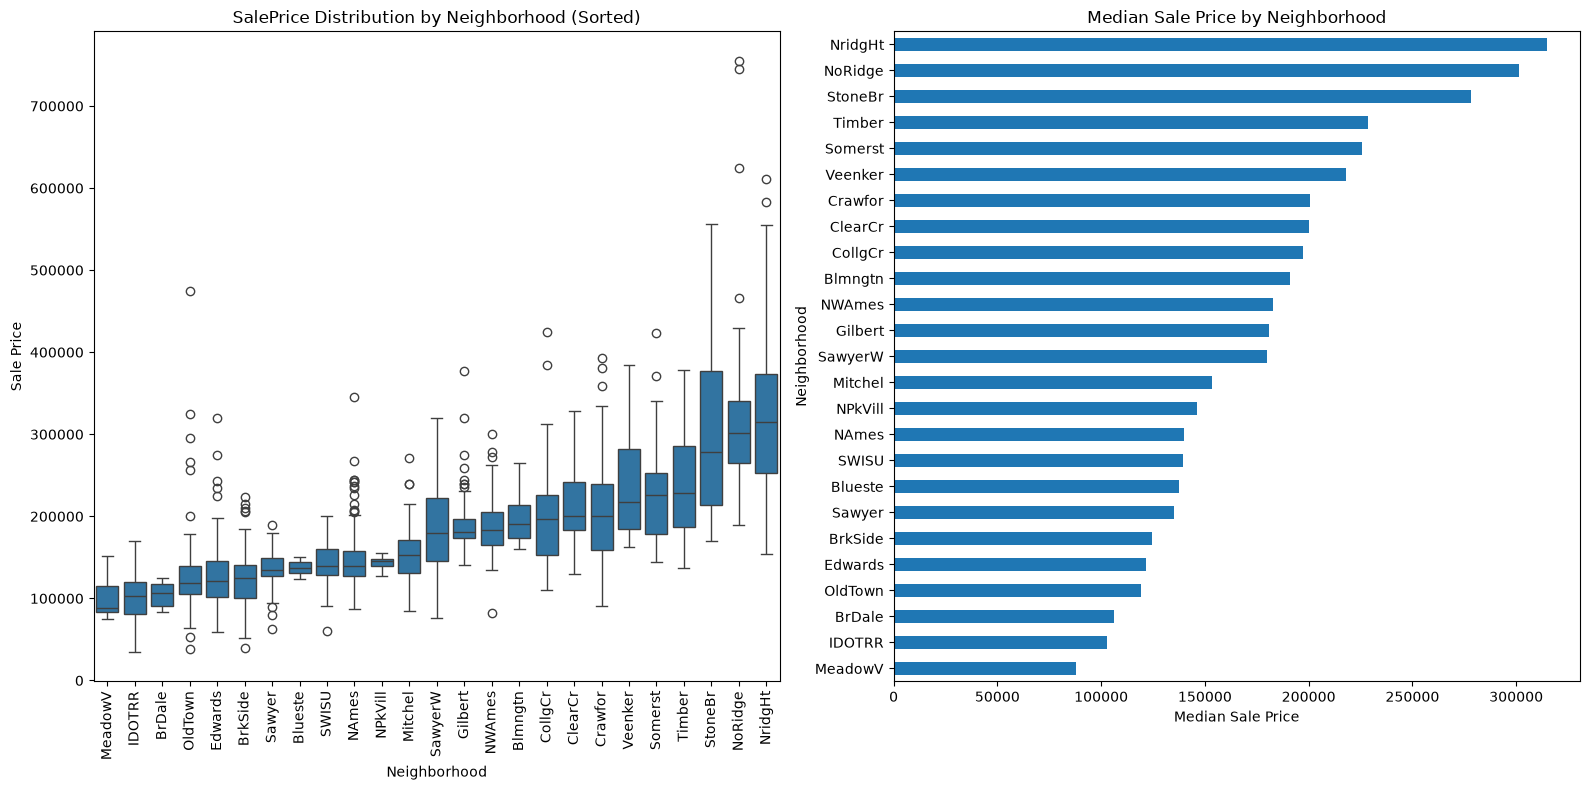

In [22]:
# 1. Calculate and sort neighborhoods by median sale price
sorted_neighborhoods = (
    df.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values(ascending=True)
)

# 2. Create 1 row with 2 columns for subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Subplot 1: Box Plot (ordered low to high by median price)
sns.boxplot(
    data=df,
    x="Neighborhood",
    y="SalePrice",
    order=sorted_neighborhoods.index,
    ax=axes[0]
)
axes[0].tick_params(axis="x", rotation=90)
axes[0].set_title("SalePrice Distribution by Neighborhood (Sorted)")
axes[0].set_xlabel("Neighborhood")
axes[0].set_ylabel("Sale Price")

# Subplot 2: Horizontal Bar Plot of Median Sale Prices
sorted_neighborhoods.plot(
    kind="barh",
    ax=axes[1],
    title="Median Sale Price by Neighborhood"
)
axes[1].set_xlabel("Median Sale Price")
axes[1].set_ylabel("Neighborhood")

# Clean up layout
plt.tight_layout()
plt.show()

#### Observations:
    Neighborhood has an η² of about 0.57, meaning neighborhood differences are strongly 
    related to differences in house prices.
    From the ploat we can see the difference in prices according to neighborhood
    the diffrence in saleprice of some of the lowest to some of the highest median  
    price neighborhood is almost 3-4 times.
    

#### Plotting Capacity colums

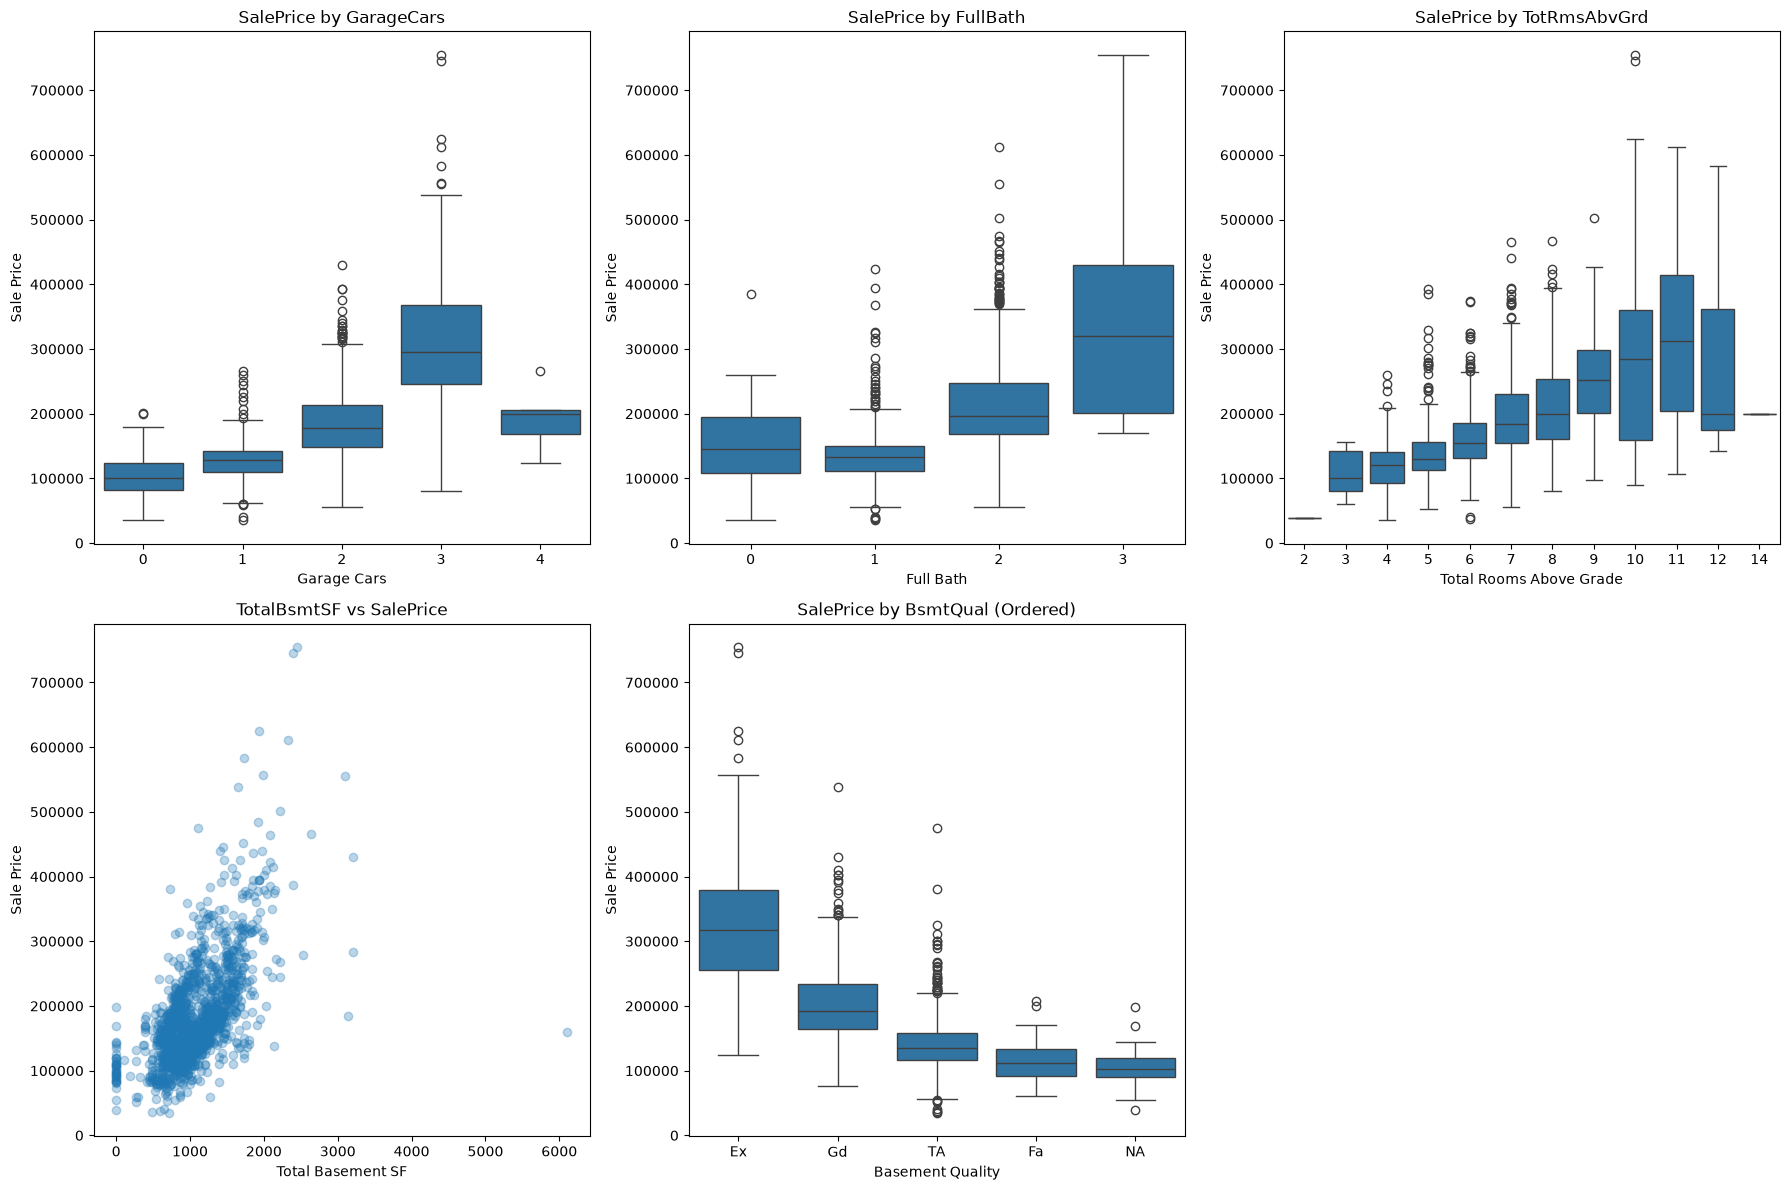

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define standard order for BsmtQual categorical plotting
bsmt_qual_order = ["Ex", "Gd", "TA", "Fa", "NA"]

# Create a figure with 2 rows and 3 columns
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# --- Row 1: The Three Categorical Boxplots ---

# Plot 1: GarageCars vs SalePrice
sns.boxplot(data=df, x="GarageCars", y="SalePrice", ax=axes[0, 0])
axes[0, 0].set_title("SalePrice by GarageCars")
axes[0, 0].set_xlabel("Garage Cars")
axes[0, 0].set_ylabel("Sale Price")

# Plot 2: FullBath vs SalePrice
sns.boxplot(data=df, x="FullBath", y="SalePrice", ax=axes[0, 1])
axes[0, 1].set_title("SalePrice by FullBath")
axes[0, 1].set_xlabel("Full Bath")
axes[0, 1].set_ylabel("Sale Price")

# Plot 3: TotRmsAbvGrd vs SalePrice
sns.boxplot(data=df, x="TotRmsAbvGrd", y="SalePrice", ax=axes[0, 2])
axes[0, 2].set_title("SalePrice by TotRmsAbvGrd")
axes[0, 2].set_xlabel("Total Rooms Above Grade")
axes[0, 2].set_ylabel("Sale Price")

# --- Row 2: The Scatter Plot and BsmtQual Boxplot ---

# Plot 4: TotalBsmtSF vs SalePrice (Scatter)
# note: Using standard scatter for subplot compatibility
axes[1, 0].scatter(df["TotalBsmtSF"], df["SalePrice"], alpha=0.3)
axes[1, 0].set_title("TotalBsmtSF vs SalePrice")
axes[1, 0].set_xlabel("Total Basement SF")
axes[1, 0].set_ylabel("Sale Price")

# Plot 5: BsmtQual vs SalePrice (Boxplot)
sns.boxplot(data=df, x="BsmtQual", y="SalePrice", order=bsmt_qual_order, ax=axes[1, 1])
axes[1, 1].set_title("SalePrice by BsmtQual (Ordered)")
axes[1, 1].set_xlabel("Basement Quality")
axes[1, 1].set_ylabel("Sale Price")

# Plot 6: Leave this subplot empty to maintain 2x3 layout integrity.
axes[1, 2].axis('off')  # Hide the empty subplot axes

# Adjust spacing between plots automatically
plt.tight_layout()
plt.show()

#### Observations:
    Capacity matters: bathrooms show a stronger price relationship than total rooms, while garage capacity shows a clear increase up to 3 cars. Basement size and quality reinforce the same size-plus-quality pattern seen elsewhere.

#### Plotting Age column:

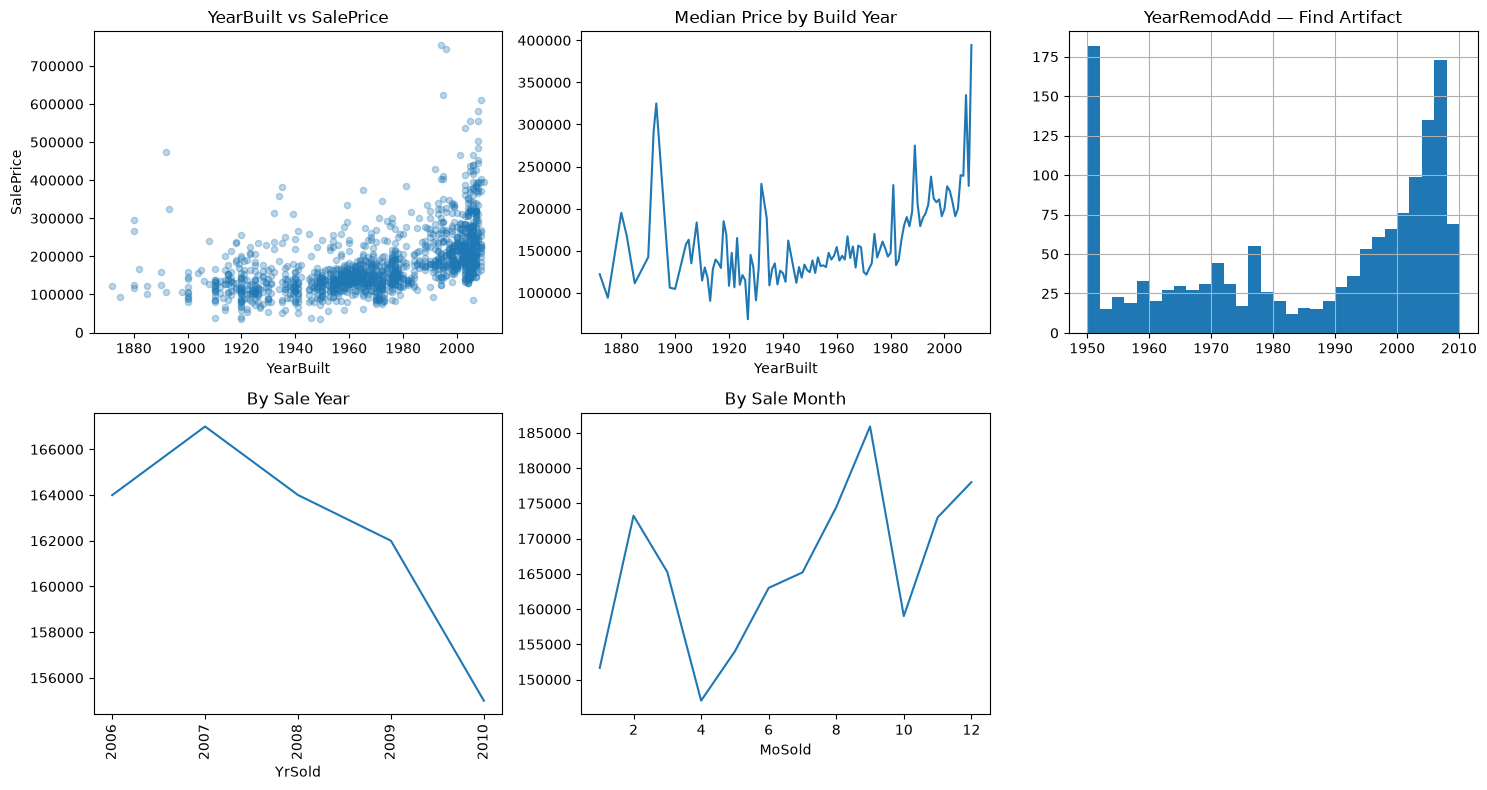

In [24]:
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

# Row 1 Plots
df.plot.scatter(x="YearBuilt", y="SalePrice", alpha=0.3, ax=axes[0], title="YearBuilt vs SalePrice")
df.groupby("YearBuilt")["SalePrice"].median().plot(ax=axes[1], title="Median Price by Build Year")
df["YearRemodAdd"].hist(bins=30, ax=axes[2]).set_title("YearRemodAdd — Find Artifact")

# Row 2 Plots: Fix YrSold tick overlap & formatting
df.groupby("YrSold")["SalePrice"].median().plot(ax=axes[3], title="By Sale Year")
axes[3].tick_params(axis="x", rotation=90)  # Make labels vertical
axes[3].xaxis.set_major_locator(MaxNLocator(integer=True))  # Force integer years only

df.groupby("MoSold")["SalePrice"].median().plot(ax=axes[4], title="By Sale Month")

# Clean up empty slot
axes[5].axis("off")
plt.tight_layout()
plt.show()

#### Observations:
    Plot 1. Newer houses generally have higher price
    Plot 2. some expensive old houses that survived created the left spike
    Plot 3. 1950 spike is data artifact = it is acting as default value for some records
            Don't blindly treat YearRemodAdd = 1950 as a genuine remodeling year.
    Plot 4. Relatively flat 166k -> 156k from 2006-2010
    Plot 5. Houses tend to sale at a bit hiher in summer.

#### Conclusion:
    Age matters, but less than quality; the 1950 remodeling spike is a data artifact; time features will be engineered later instead of using the raw year/month columns.

#### Plotting column OverallCond:

corr: -0.078


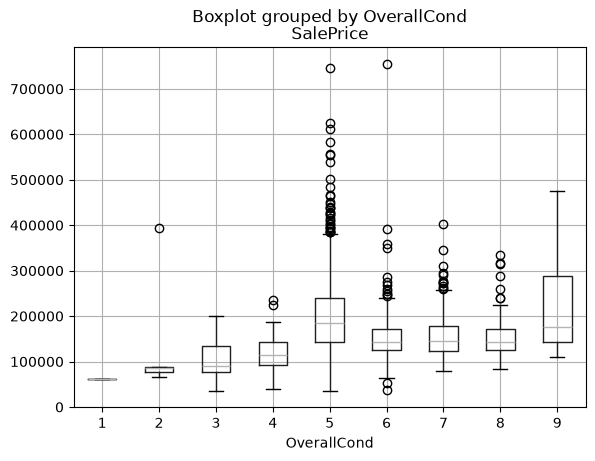

In [25]:
df.boxplot(column="SalePrice", by="OverallCond")
print("corr:", round(df["OverallCond"].corr(df["SalePrice"]), 3))

#### Observation:
    Overall condition has almost no relationship with price (correlation ≈ −0.08), while overall quality is a strong price signal.

#### Outdoor columns:

In [26]:
for col in ["WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "ScreenPorch", "3SsnPorch", "PoolArea"]:
    print(f"{col}: {(df[col] == 0).mean():.1%} of houses have zero")

WoodDeckSF: 52.1% of houses have zero
OpenPorchSF: 44.9% of houses have zero
EnclosedPorch: 85.8% of houses have zero
ScreenPorch: 92.1% of houses have zero
3SsnPorch: 98.4% of houses have zero
PoolArea: 99.5% of houses have zero


#### Observation:
    Most of the values are 0.
    Most outdoor features are absent in a large majority of houses, so their 
    presence/absence may be more useful than their raw area individually.

#### Plotting sale context columns:

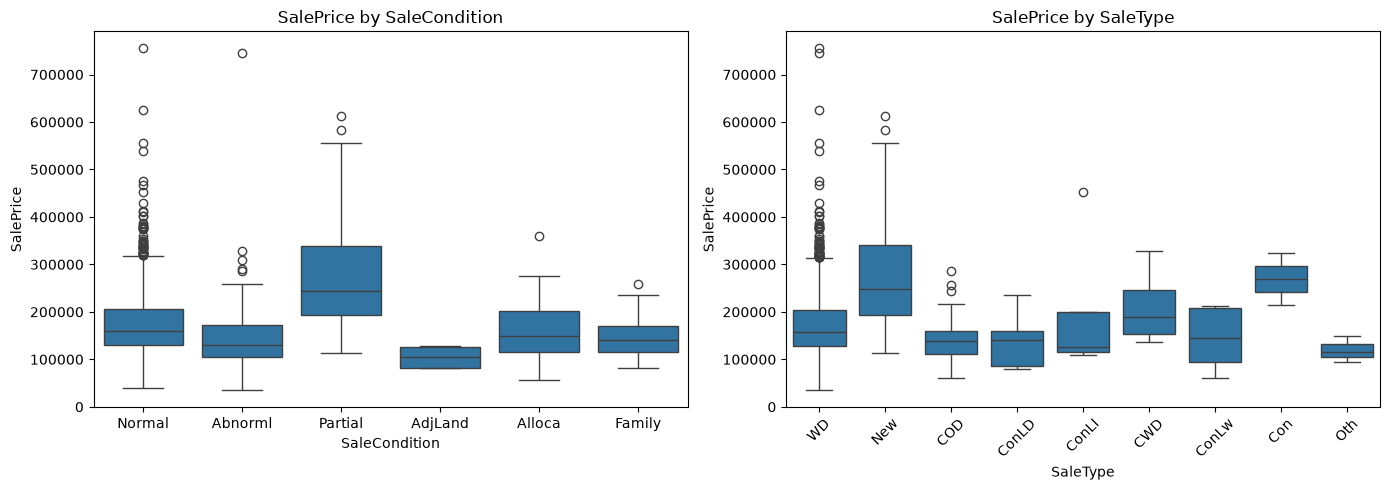

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="SaleCondition", y="SalePrice", ax=axes[0]).set(title="SalePrice by SaleCondition")
sns.boxplot(data=df, x="SaleType", y="SalePrice", ax=axes[1]).set(title="SalePrice by SaleType")

axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

#### Observation:
    Partial sales form a distinct transaction group, often involving new homes sold before completion, helping explain the unusual low-price/large-area outliers identified earlier

#### Checking for Redundancy

In [28]:
pairs = num_corr.abs().unstack()
pairs = pairs[(pairs > 0.8) & (pairs < 1.0)].sort_values(ascending=False)
print(pairs.iloc[::2])   # each pair listed twice — keep every other

GarageCars  GarageArea      0.882475
YearBuilt   GarageYrBlt     0.825667
GrLivArea   TotRmsAbvGrd    0.825489
1stFlrSF    TotalBsmtSF     0.819530
dtype: float64


#### Observations:
    Several numeric features are highly redundant: garage area with garage capacity, build year with garage year, living area with room count, and basement area with first-floor area.

#### Mechanical Outlier sweeps:

In [29]:
flags = {}
for col in df.select_dtypes("number").drop(columns=["Id", "SalePrice"]).columns:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 3*iqr) | (df[col] > q3 + 3*iqr)).sum()
    if n:
        flags[col] = int(n)
print(flags)

{'LotFrontage': 12, 'LotArea': 34, 'OverallCond': 1, 'MasVnrArea': 25, 'BsmtFinSF1': 1, 'BsmtFinSF2': 167, 'TotalBsmtSF': 5, '1stFlrSF': 3, 'LowQualFinSF': 26, 'GrLivArea': 4, 'BsmtHalfBath': 82, 'BedroomAbvGr': 1, 'KitchenAbvGr': 68, 'TotRmsAbvGrd': 1, 'GarageArea': 3, 'WoodDeckSF': 3, 'OpenPorchSF': 18, 'EnclosedPorch': 208, '3SsnPorch': 24, 'ScreenPorch': 116, 'PoolArea': 7, 'MiscVal': 52}


#### Observation: 
    The mechanical sweep flagged 22 columns and found zero data errors. On zero-inflated columns the IQR rule degenerates (Q1=Q3 → IQR=0 → fence=Q3 → every nonzero value flagged), so those counts are inventories of feature-havers, not anomalies — which independently supports converting them to binary flags in Phase 2. On continuous columns, flags mark legitimate high-value tails, verified as extreme-but-on-trend against the scatterplots. The only removals remain Ids 524 and 1299 — decided on domain grounds (partial sales), not by any mechanical rule. Rules flag; reasons decide.

### PER COLUMN CONCLUSION:

###### Group A — Rule artifact (IQR≈0). Flags = feature-havers. No action.

EnclosedPorch(208) = every house WITH an enclosed porch (~86% have none)

BsmtFinSF2(167)	= every house with Type-2 finished basement area

ScreenPorch(116) = every house with a screen porch

BsmtHalfBath(82) = every house with a basement half-bath

KitchenAbvGr(68) = every house with ≠1 kitchen — the duplex/low-end segment (cross-links to Q2's most-negative, −0.14)

MiscVal(52) = every house with a valued misc feature

LowQualFinSF(26) = every house with any low-quality finished space

3SsnPorch(24) = every house with a three-season porch

PoolArea(7) = the 7 pools


###### Group B — Legitimate continuous tails. Wealth, not errors. Keep all.

LotArea(34) = large lots/acreage — a real market segment

MasVnrArea(25) = heavy masonry on large houses

OpenPorchSF(18) = oversized porches

LotFrontage(12) = large street frontages (corner/golf lots)

TotalBsmtSF(5) = enormous basements (includes the biggest houses)

1stFlrSF(3) = huge first floors

GarageArea(3) = huge garages

WoodDeckSF(3) = oversized decks


###### Group C — Singletons. Unusual but real houses. Keep.

BsmtFinSF1(1) = the single largest finished basement

BedroomAbvGr(1)	= the one 8-bedroom house

TotRmsAbvGrd(1) = the one 14-room house

OverallCond(1) = the single lowest-condition-rated house


###### Group D — GrLivArea

GrLivArea(4) = exactly the four >4,000 sqft houses from the scatter — independent confirmation. Keep 692 & 1183 (on-trend), drop 524 & 1299 (partial sales)



#### Key Findings:
    1. Target data (SalePrice) is right skewed.(1.88)
    2. top 5 numerical columns that have high positive corelation with SalePrice
        OverallQual | GrLivArea | GarageCars | GarageArea | TotalBsmtSF 
    3. Top 5 categorical column that have high share of price variance 
        OverallQual | Neighborhood | ExterQual | BsmtQual | KitchenQual
    4. Most Area related columns shows strongers relationship with price
        GrLivArea = Strongest indicator
        LotArea = weak and messy indicator
    5. id 524 and id 1299 are outliers that need to be removed.
        "(Partial sales — incomplete transactions; price doesn't reflect completed 
        market value)".
    6. Quality is one of the strongest and most consistent factors associated with 
        SalePrice in this dataset.
    7. Age matters, but less than quality; the 1950 remodeling spike is a data artifact
    8. Overall condition has almost no relationship with price (correlation ≈ −0.08), 
        while overall quality is a strong price signal.
    9. Most outdoor features are absent in a large majority of houses, so their 
        presence/absence may be more useful than their raw area individually.
    10. Several numeric features are highly redundant: garage area with garage 
         capacity, build year with garage year, living area with room count, and 
         basement area with first-floor area.
         "handled by regularized linear models + trees; both features kept."
    11. "MSSubClass reads as noise as a number (corr −0.08) but explains 33% of price 
         variance as a category (η²) — must be recast
         

## TASK 1 - EDA REPORT

### Dataset snapshot

Rows    = 1460 houses(Ames, Iowa, sales 2006-2010)

Columns = 81  - 1 Target, 1 ID, 79 features

Traget  = SalePrice  $ 34,900 - $ 755,000, median = $163,000

Missingness = 19 columns affected (14 absence-by-design, 5 genuine)

Evalution   = No test set -> 5 fold CV + 20% holdout


### Method

Two association maps
1. Pearson correlation - for numeric features
2. ANOVA F and η² for categorical. η² (share of price variance explained) is theranking
   measure, because raw F structurally penalizes columns with manycategories.

### 2.1 The Trarget = SalePrice

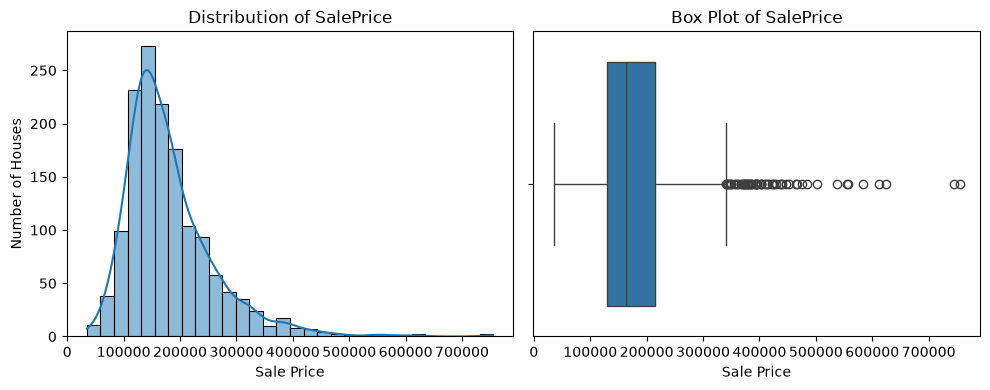

In [30]:
# Create a figure with 1 row and 2 columns of subplots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Plot 1: Histogram (Left Subplot)
sns.histplot(
    data=df,
    x="SalePrice",
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of SalePrice")
axes[0].set_xlabel("Sale Price")
axes[0].set_ylabel("Number of Houses")

# Plot 2: Box Plot (Right Subplot)
sns.boxplot(
    data=df,
    x="SalePrice",
    ax=axes[1]
)
axes[1].set_title("Box Plot of SalePrice")
axes[1].set_xlabel("Sale Price")

# Adjust spacing between subplots
plt.tight_layout()
plt.show()

SalePrice ranges from 34,900 dollers to 755,000 dollers with a median of 163,000 dollers. Thedistribution is strongly right-skewed (skew = 1.88) the middle 50% of housessit between 130K and 214K, while a small tail of expensive homes stretchesto 4.6× the median.

Implication:
We model log1p(SalePrice): without the transform, squarederror is dominated by the expensive tail. After log1p, skew drops to 0.12.Primary metric: RMSE on log price; secondary: dollar MAE.

### 2.2 Quality

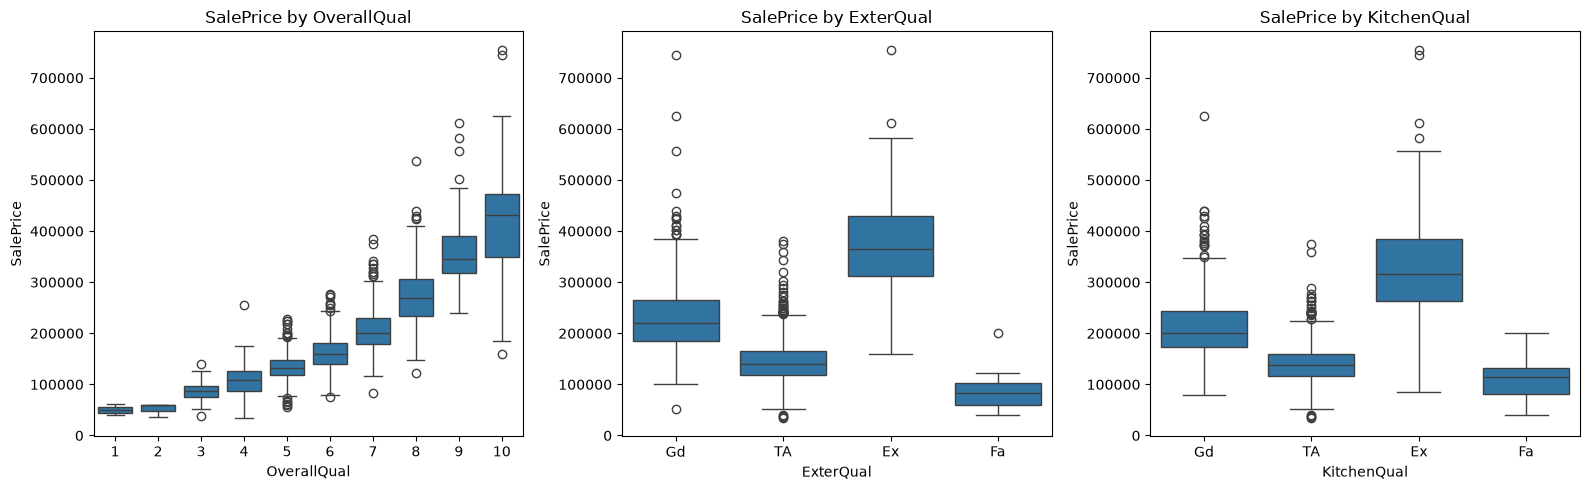

In [31]:
cols = ["OverallQual", "ExterQual", "KitchenQual"]

# Create 1 row with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(cols):
    sns.boxplot(
        data=df,
        x=col,
        y="SalePrice",
        ax=axes[i]
    )
    axes[i].set_title(f"SalePrice by {col}")

plt.tight_layout()
plt.show()

Quality is one of the strongest and most consistent factors associated with 
SalePrice in this dataset.
all three plots show same progression quality increase assciated with price increase
η²: 
OverallQual 0.67, ExterQual 0.46, BsmtQual 0.45, KitchenQual 0.45

Implication:
ordinal encoding preserves the order

### 2.3 Size:

<Axes: title={'center': 'GrLivArea vs SalePrice'}, xlabel='GrLivArea', ylabel='SalePrice'>

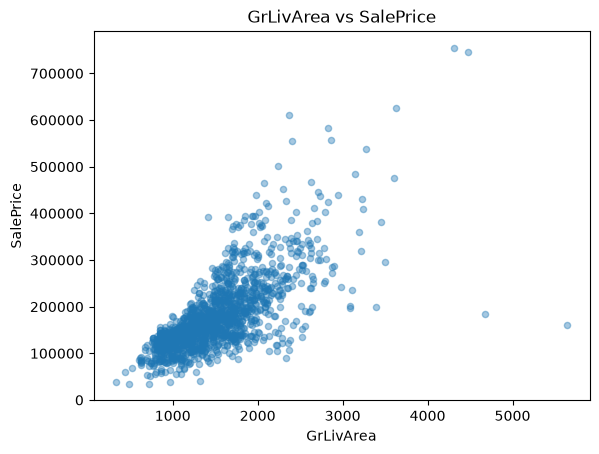

In [32]:
df.plot.scatter(x="GrLivArea", y="SalePrice", alpha=0.4, title="GrLivArea vs SalePrice")

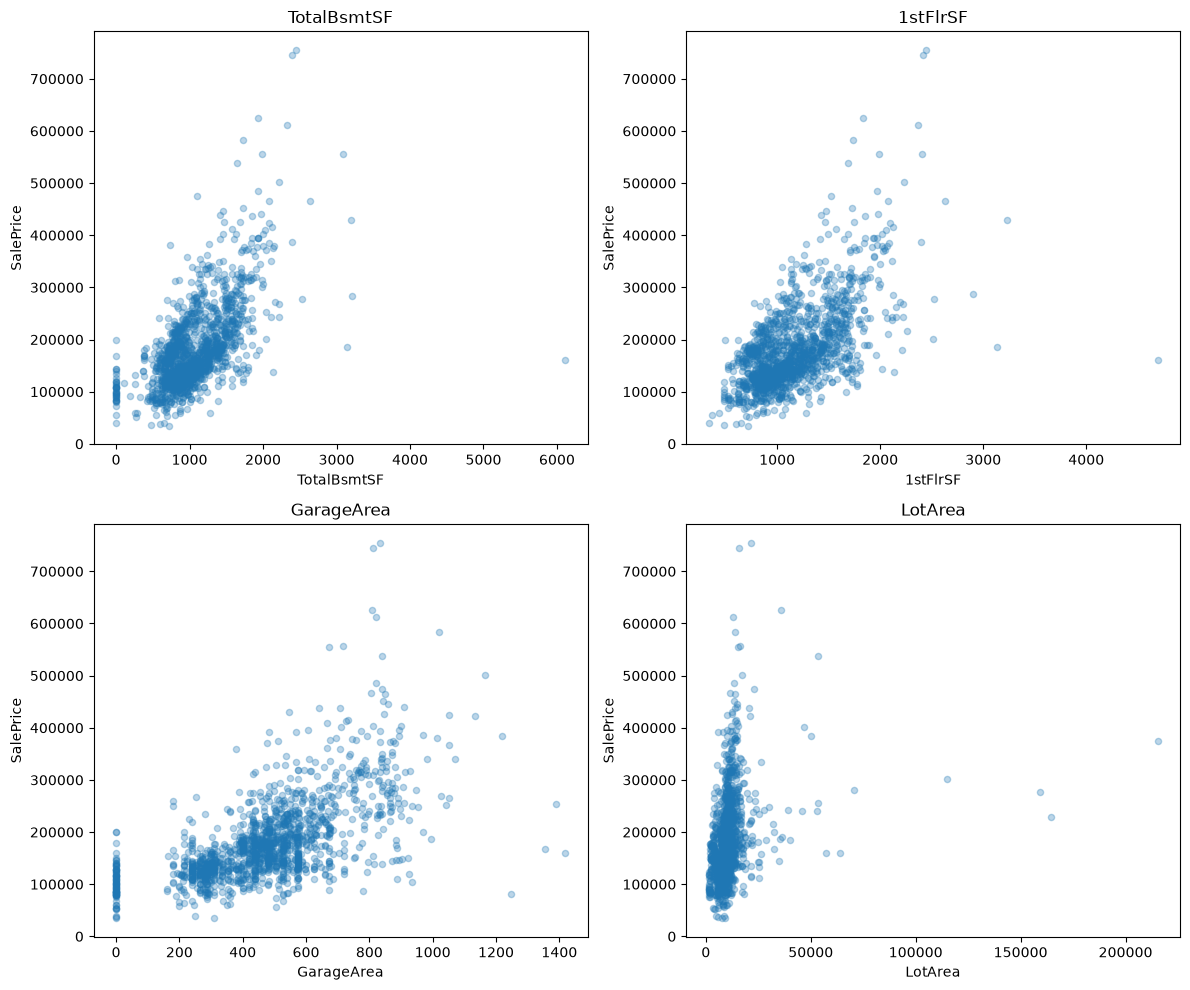

In [33]:
cols = ["TotalBsmtSF", "1stFlrSF", "GarageArea", "LotArea"]

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Flatten 2D axes array (2, 2) into a 1D array (4,) for easier iteration
axes = axes.flatten()

# Plot each column on its corresponding subplot axis
for i, col in enumerate(cols):
    df.plot.scatter(
        x=col,
        y="SalePrice",
        alpha=0.3,
        title=col,
        ax=axes[i]
    )

# Adjust layout to prevent overlapping labels
plt.tight_layout()
plt.show()

ALL Five charts about size show same story.
AS size increases the price also increases.
GrLivArea = 0.71 has the strongest corelation with SalePrice.
While LotArea has weak relationship and is noisy.

Implication:
TotalSF engineered in Phase 2

### 2.4 Location:

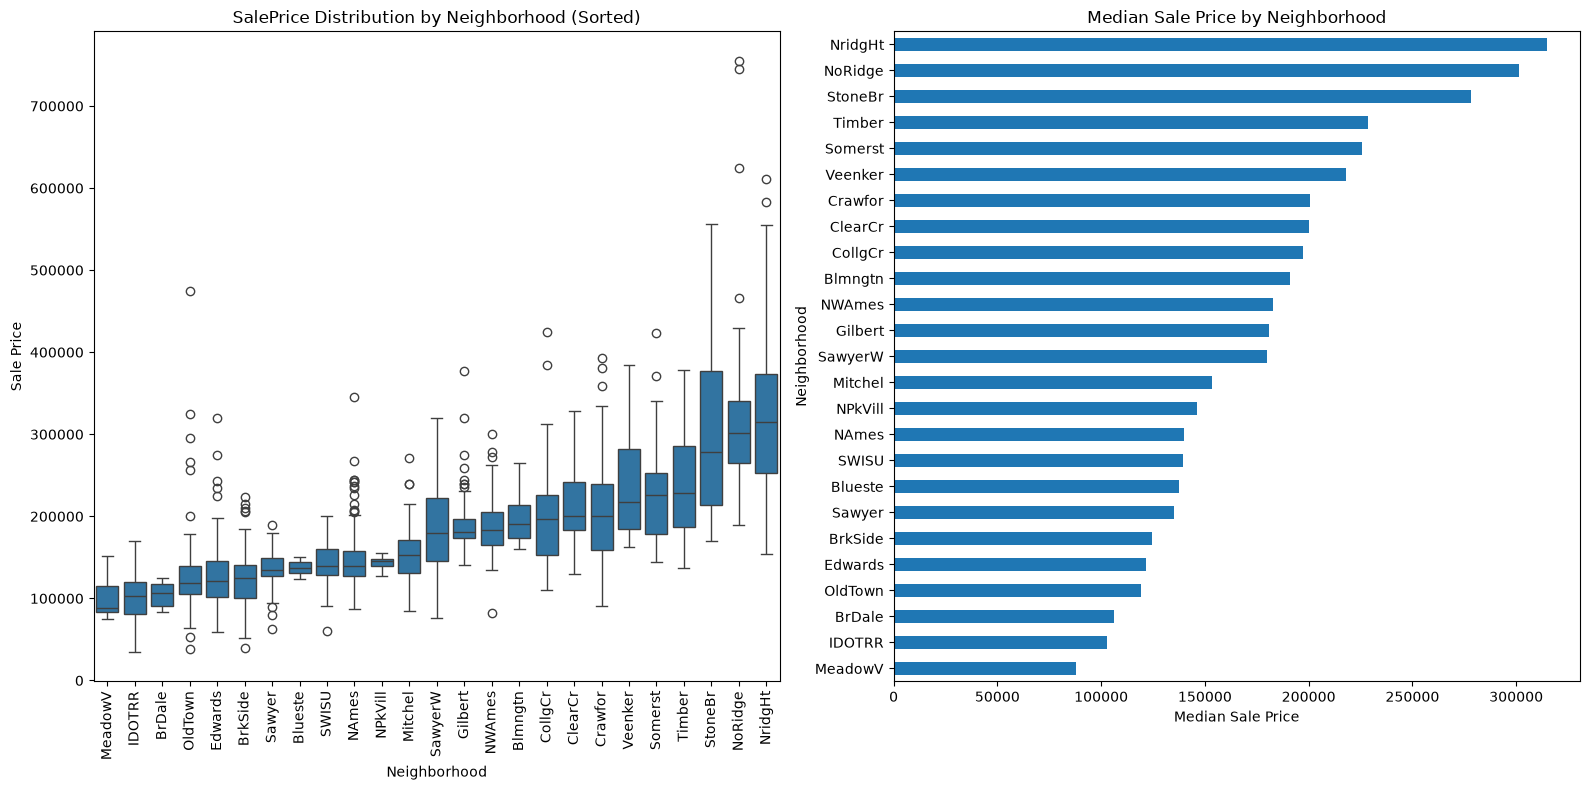

In [34]:
# 1. Calculate and sort neighborhoods by median sale price
sorted_neighborhoods = (
    df.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values(ascending=True)
)

# 2. Create 1 row with 2 columns for subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Subplot 1: Box Plot (ordered low to high by median price)
sns.boxplot(
    data=df,
    x="Neighborhood",
    y="SalePrice",
    order=sorted_neighborhoods.index,
    ax=axes[0]
)
axes[0].tick_params(axis="x", rotation=90)
axes[0].set_title("SalePrice Distribution by Neighborhood (Sorted)")
axes[0].set_xlabel("Neighborhood")
axes[0].set_ylabel("Sale Price")

# Subplot 2: Horizontal Bar Plot of Median Sale Prices
sorted_neighborhoods.plot(
    kind="barh",
    ax=axes[1],
    title="Median Sale Price by Neighborhood"
)
axes[1].set_xlabel("Median Sale Price")
axes[1].set_ylabel("Neighborhood")

# Clean up layout
plt.tight_layout()
plt.show()

Neighborhood has an η² of about 0.57, meaning neighborhood differences are strongly 
related to differences in house prices.
From the plot we can see the difference in prices according to neighborhood
the diffrence in saleprice of some of the lowest to some of the highest median  
price neighborhood is almost 3-4 times.

Implication:
25 levels → one-hot in pipeline

### 2.5 Capacity

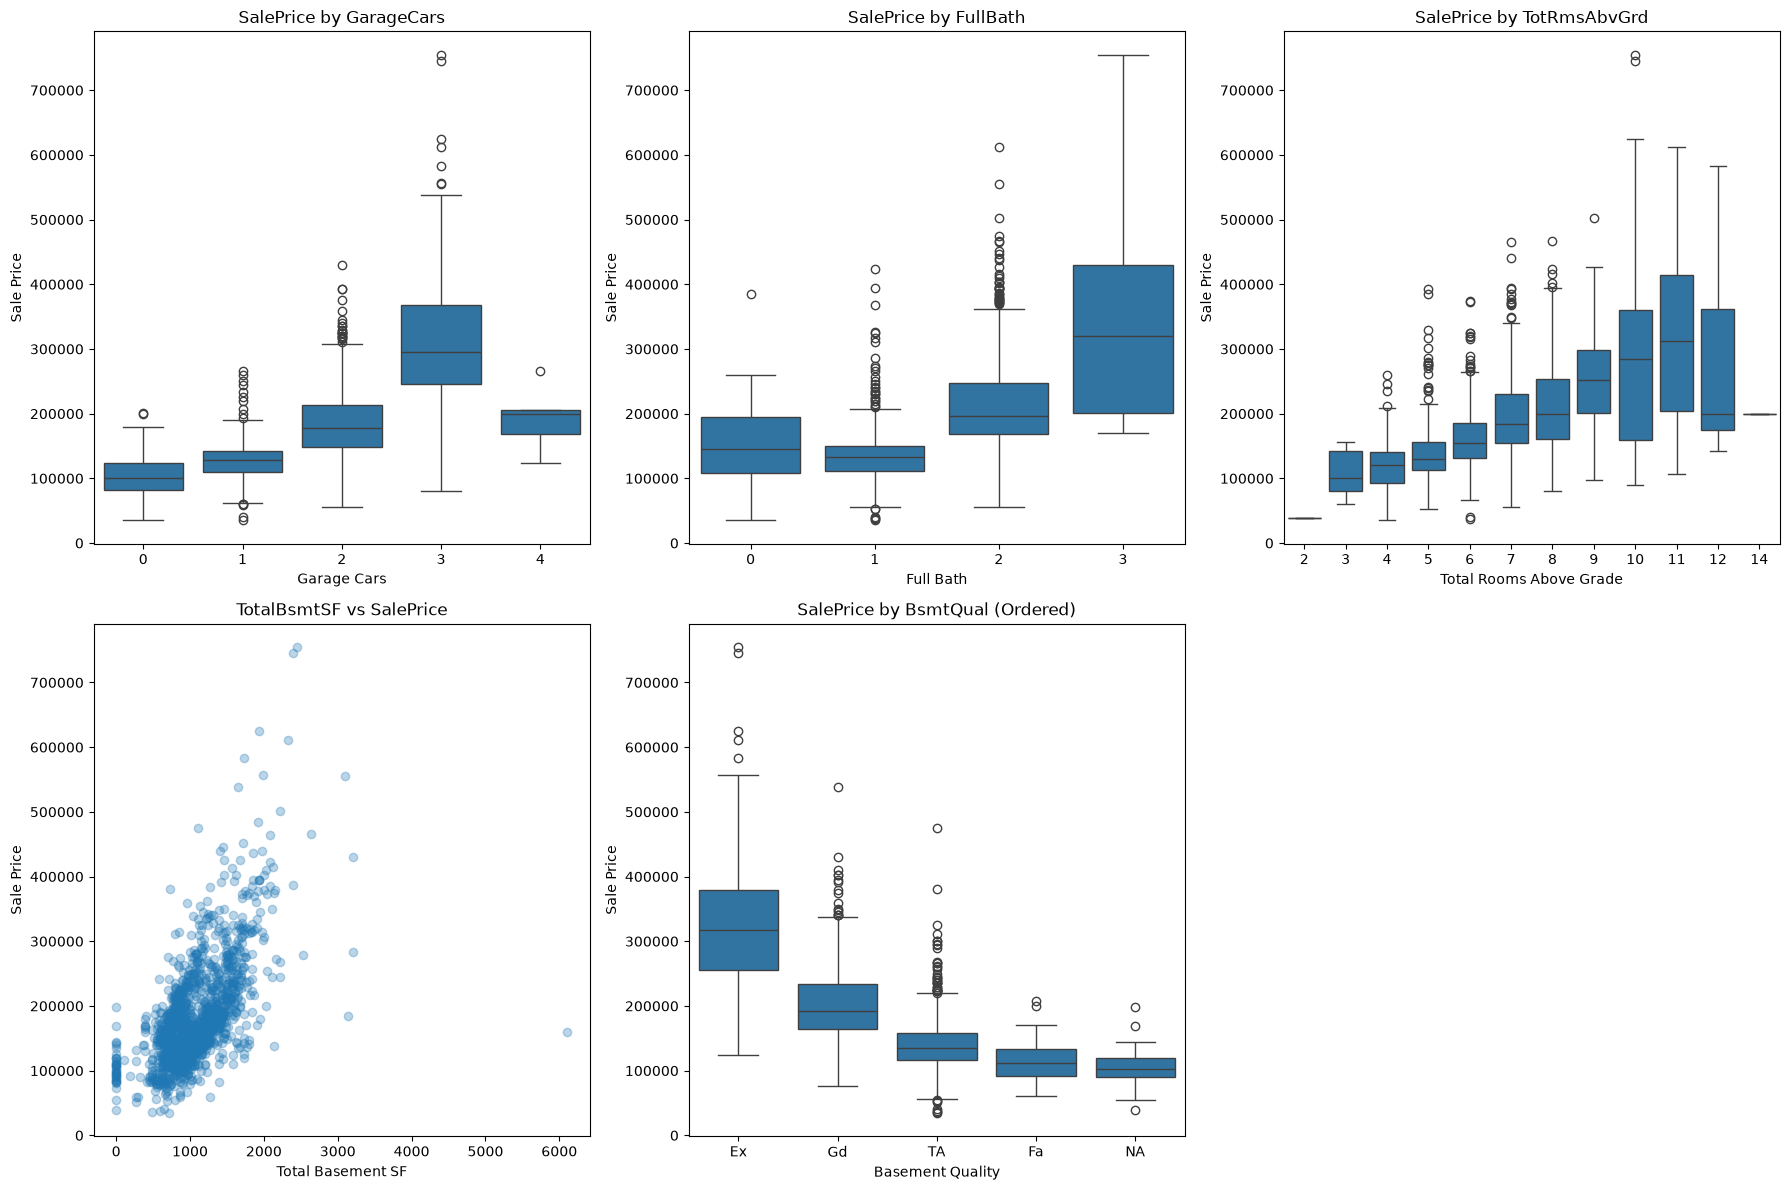

In [35]:
# Define standard order for BsmtQual categorical plotting
bsmt_qual_order = ["Ex", "Gd", "TA", "Fa", "NA"]

# Create a figure with 2 rows and 3 columns
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# --- Row 1: The Three Categorical Boxplots ---

# Plot 1: GarageCars vs SalePrice
sns.boxplot(data=df, x="GarageCars", y="SalePrice", ax=axes[0, 0])
axes[0, 0].set_title("SalePrice by GarageCars")
axes[0, 0].set_xlabel("Garage Cars")
axes[0, 0].set_ylabel("Sale Price")

# Plot 2: FullBath vs SalePrice
sns.boxplot(data=df, x="FullBath", y="SalePrice", ax=axes[0, 1])
axes[0, 1].set_title("SalePrice by FullBath")
axes[0, 1].set_xlabel("Full Bath")
axes[0, 1].set_ylabel("Sale Price")

# Plot 3: TotRmsAbvGrd vs SalePrice
sns.boxplot(data=df, x="TotRmsAbvGrd", y="SalePrice", ax=axes[0, 2])
axes[0, 2].set_title("SalePrice by TotRmsAbvGrd")
axes[0, 2].set_xlabel("Total Rooms Above Grade")
axes[0, 2].set_ylabel("Sale Price")

# --- Row 2: The Scatter Plot and BsmtQual Boxplot ---

# Plot 4: TotalBsmtSF vs SalePrice (Scatter)
# note: Using standard scatter for subplot compatibility
axes[1, 0].scatter(df["TotalBsmtSF"], df["SalePrice"], alpha=0.3)
axes[1, 0].set_title("TotalBsmtSF vs SalePrice")
axes[1, 0].set_xlabel("Total Basement SF")
axes[1, 0].set_ylabel("Sale Price")

# Plot 5: BsmtQual vs SalePrice (Boxplot)
sns.boxplot(data=df, x="BsmtQual", y="SalePrice", order=bsmt_qual_order, ax=axes[1, 1])
axes[1, 1].set_title("SalePrice by BsmtQual (Ordered)")
axes[1, 1].set_xlabel("Basement Quality")
axes[1, 1].set_ylabel("Sale Price")

# Plot 6: Leave this subplot empty to maintain 2x3 layout integrity.
axes[1, 2].axis('off')  # Hide the empty subplot axes

# Adjust spacing between plots automatically
plt.tight_layout()
plt.show()

Capacity matters: bathrooms show a stronger price relationship than total rooms, while garage capacity shows a clear increase up to 3 cars. Basement size and quality reinforce the same size-plus-quality pattern seen elsewhere.

Implication:
Counts kept as in.

### 2.5 Age

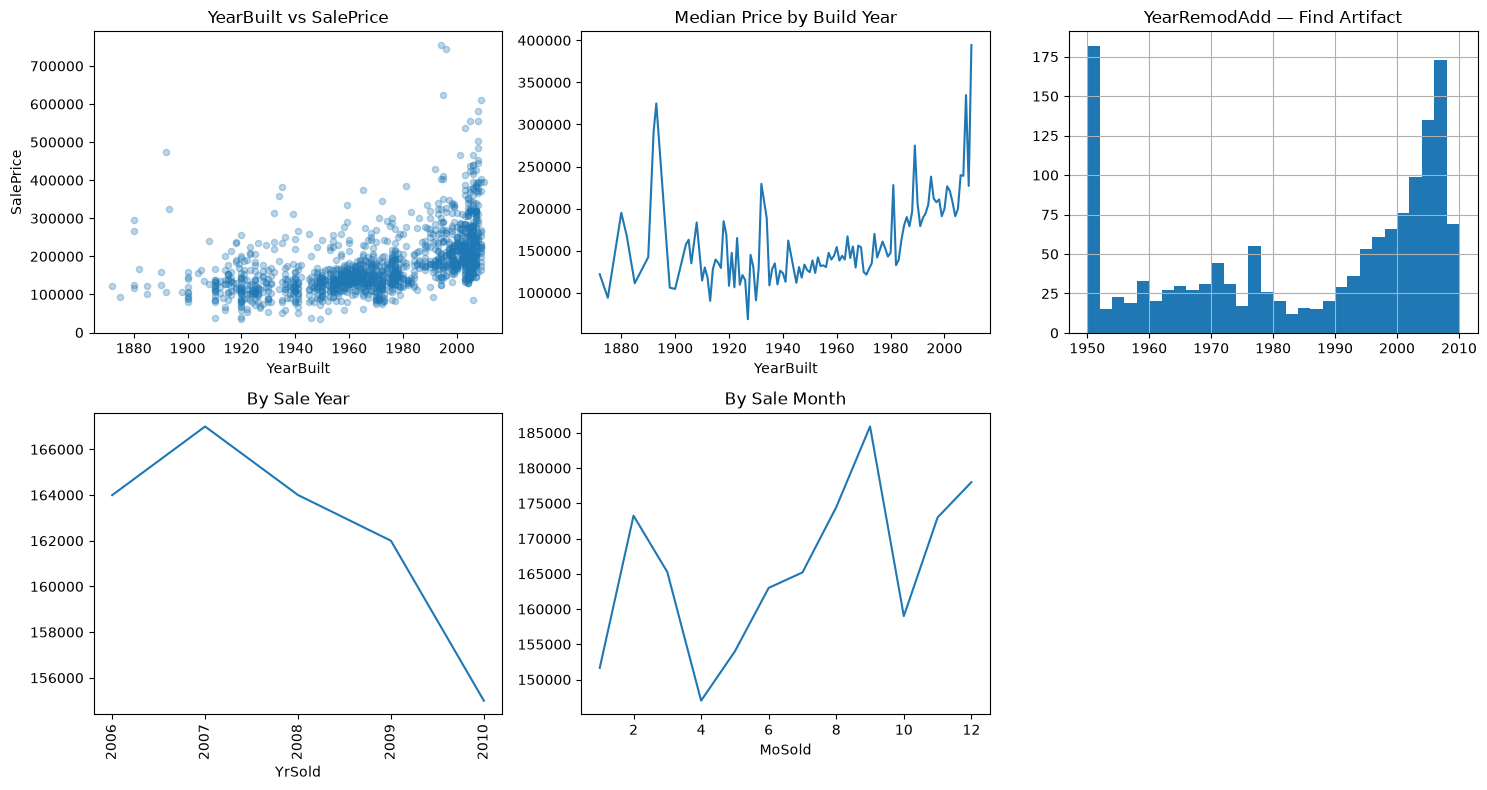

In [36]:
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

# Row 1 Plots
df.plot.scatter(x="YearBuilt", y="SalePrice", alpha=0.3, ax=axes[0], title="YearBuilt vs SalePrice")
df.groupby("YearBuilt")["SalePrice"].median().plot(ax=axes[1], title="Median Price by Build Year")
df["YearRemodAdd"].hist(bins=30, ax=axes[2]).set_title("YearRemodAdd — Find Artifact")

# Row 2 Plots: Fix YrSold tick overlap & formatting
df.groupby("YrSold")["SalePrice"].median().plot(ax=axes[3], title="By Sale Year")
axes[3].tick_params(axis="x", rotation=90)  # Make labels vertical
axes[3].xaxis.set_major_locator(MaxNLocator(integer=True))  # Force integer years only

df.groupby("MoSold")["SalePrice"].median().plot(ax=axes[4], title="By Sale Month")

# Clean up empty slot
axes[5].axis("off")
plt.tight_layout()
plt.show()

Newer houses generally have higher price.
some expensive old houses that survived created the left spike.
1950 spike is data artifact = it is acting as default value for some records.
Don't blindly treat YearRemodAdd = 1950 as a genuine remodeling year.
Relatively flat 166k -> 156k from 2006-2010
Houses tend to sale at a bit hiher in summer.

Age matters, but less than quality

Implication:
engineer HouseAge/IsRemodeled, not raw years.

### 2.6 What doesn't matter

Overall condition has almost no relationship with price (correlation ≈ −0.08), while overall quality is a strong price signal.

Zero values in this columns

WoodDeckSF: 52.1% | OpenPorchSF: 44.9% | EnclosedPorch: 85.8% | ScreenPorch: 92.1% | 3SsnPorch: 98.4% | PoolArea: 99.5% 

Most of the values are 0.
Most outdoor features are absent in a large majority of houses, so their 
presence/absence may be more useful than their raw area individually.

Implication:
outdoor -> binary flags

### 2.7 Outlier and Data Quality

<Axes: title={'center': 'GrLivArea vs SalePrice'}, xlabel='GrLivArea', ylabel='SalePrice'>

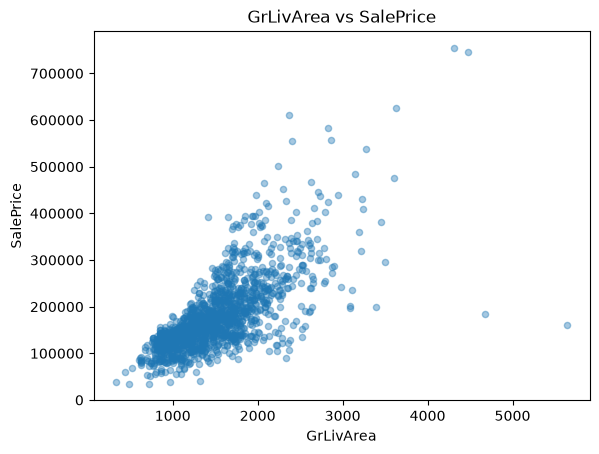

In [37]:
df.plot.scatter(x="GrLivArea", y="SalePrice", alpha=0.4, title="GrLivArea vs SalePrice")

In [38]:
# now check the extreme houses:
big = df[df['GrLivArea'] > 4000]
print(big[['Id', 'GrLivArea', 'SalePrice', 'OverallQual', 'YearBuilt', 'SaleCondition']])

        Id  GrLivArea  SalePrice  OverallQual  YearBuilt SaleCondition
523    524       4676     184750           10       2007       Partial
691    692       4316     755000           10       1994        Normal
1182  1183       4476     745000           10       1996       Abnorml
1298  1299       5642     160000           10       2008       Partial



we caught 4 extreme values 2 of them are plausible but other 2 contradict. 

id 524 and id 1299 have big square footage but low price. We conclude their saleprice does not reflect market value and it may mislead the model.

524/1299 removed (Partial — domain reason); 692/1183 kept; sweep found zero data errors (IQR degenerates on zero-inflated columns)

Implication: rules flag, reason decide

### 2.8 Redundancy

In [39]:
pairs = num_corr.abs().unstack()
pairs = pairs[(pairs > 0.8) & (pairs < 1.0)].sort_values(ascending=False)
print(pairs.iloc[::2])   # each pair listed twice — keep every other

GarageCars  GarageArea      0.882475
YearBuilt   GarageYrBlt     0.825667
GrLivArea   TotRmsAbvGrd    0.825489
1stFlrSF    TotalBsmtSF     0.819530
dtype: float64


Several numeric features are highly redundant: garage area with garage capacity, build year with garage year, living area with room count, and basement area with first-floor area.

Implication:
Ridge/Lasso + trees: both members kept

### Key Findings:
    1. Target data (SalePrice) is right skewed.(1.88)
    2. top 5 numerical columns that have high positive corelation with SalePrice
        OverallQual | GrLivArea | GarageCars | GarageArea | TotalBsmtSF 
    3. Top 5 categorical column that have high share of price variance 
        OverallQual | Neighborhood | ExterQual | BsmtQual | KitchenQual
    4. Most Area related columns shows strongers relationship with price
        GrLivArea = Strongest indicator
        LotArea = weak and messy indicator
    5. id 524 and id 1299 are outliers that need to be removed.
        "(Partial sales — incomplete transactions; price doesn't reflect completed 
        market value)".
    6. Quality is one of the strongest and most consistent factors associated with 
        SalePrice in this dataset.
    7. Age matters, but less than quality; the 1950 remodeling spike is a data artifact
    8. Overall condition has almost no relationship with price (correlation ≈ −0.08), 
        while overall quality is a strong price signal.
    9. Most outdoor features are absent in a large majority of houses, so their 
        presence/absence may be more useful than their raw area individually.
    10. Several numeric features are highly redundant: garage area with garage 
         capacity, build year with garage year, living area with room count, and 
         basement area with first-floor area.
         "handled by regularized linear models + trees; both features kept."
    11. "MSSubClass reads as noise as a number (corr −0.08) but explains 33% of price 
         variance as a category (η²) — must be recast
         

## 3. Task 2a

### 3.1 Cleaning and feature engineering

##### Dropping record id 524 and 1299.
Entry 10. Partial sales, price != market value

##### Drop near-zero variance columns (EDA Finding: Utilities 1459/1460 AllPub, Street ~99.7% Pave)

In [40]:
# Dropping id 524 and id 1299 records
# Entry 10. Partial sales, price != market value
before = df.shape[0]
df = df[df["Id"].isin([524, 1299]) == False]
print(f"Dropped {before - df.shape[0]} rows")

# Drop near-zero variance columns (EDA Finding: Utilities 1459/1460 AllPub, Street ~99.7% Pave)
df = df.drop(columns=["Utilities", "Street"])

Dropped 2 rows


##### Imputing Id 949 and Id 333 missing values

1. Id 949: has a 936 sqft basement, exposure unknown
→ mode among houses that HAVE basements (not all houses)

2. Id 333: BsmtFinSF2 = 479 → finished Type-2 area exists, grade unknown
→ mode among houses with BsmtFinSF2 > 0 (never "Unf" — contradicts finished area)


In [41]:
#1
basemented = (df["TotalBsmtSF"] > 0) & (df["BsmtExposure"] != "NA")
mode_exposure = df.loc[basemented, "BsmtExposure"].mode()[0]
df.loc[df["Id"] == 949, "BsmtExposure"] = mode_exposure
print("BsmtExposure mode (basemented houses):", mode_exposure)

#2
has_fin2 = (df["BsmtFinSF2"] > 0) & (df["BsmtFinType2"] != "NA")
mode_fin2 = df.loc[has_fin2, "BsmtFinType2"].mode()[0]
df.loc[df["Id"] == 333, "BsmtFinType2"] = mode_fin2
print("BsmtFinType2 mode (SF2>0 houses):", mode_fin2)

BsmtExposure mode (basemented houses): No
BsmtFinType2 mode (SF2>0 houses): Rec


##### Treating missing values in columns

In [42]:
ABSENCE_COLS = ["Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
                "BsmtFinType2", "FireplaceQu", "GarageType", "GarageFinish",
                "GarageQual", "GarageCond", "PoolQC", "Fence", "MiscFeature"]

for col in ABSENCE_COLS:
    df[col] = df[col].replace("NA", "None")  

##### For MasVnrType: the 8 "NA" are genuine missing -> "None"
- likeliest no veneer
- documented in classification table

In [43]:
df["MasVnrType"] = df["MasVnrType"].replace("NA", "None")
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

##### Creating new feature 
- HasGarage

##### Filling missing year column in GarageYrBlt

In [44]:
df["HasGarage"] = (df["GarageArea"] > 0).astype(int)
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])

##### For Electrical column
- has 1 missing value we will convert it to NaN and then impute it in pipeline to prevent data leakage

In [45]:
df["Electrical"] = df["Electrical"].replace("NA", np.nan)

##### Making column values ORDINAL
- Using documentation data
- absence is considered as zero

In [46]:
QUAL_MAP     = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "None": 0}
EXPOSURE_MAP = {"Gd": 4, "Av": 3, "Mn": 2, "No": 1, "None": 0}
FIN_MAP      = {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1, "None": 0}
GARFIN_MAP   = {"Fin": 3, "RFn": 2, "Unf": 1, "None": 0}
FUNCTIONAL_MAP = {"Typ": 8, "Min1": 7, "Min2": 6, "Mod": 5, "Maj1": 4, "Maj2": 3, "Sev": 2, "Sal": 1}
FENCE_MAP    = {"GdPrv": 4, "MnPrv": 3, "GdWo": 2, "MnWw": 1, "None": 0}
LOTSHAPE_MAP = {"Reg": 4, "IR1": 3, "IR2": 2, "IR3": 1}
SLOPE_MAP    = {"Gtl": 3, "Mod": 2, "Sev": 1}
PAVED_MAP    = {"Y": 2, "P": 1, "N": 0}
AIR_MAP      = {"Y": 1, "N": 0}

ORDINAL_MAPS = {
    "ExterQual": QUAL_MAP, "ExterCond": QUAL_MAP, "HeatingQC": QUAL_MAP,
    "KitchenQual": QUAL_MAP, "BsmtQual": QUAL_MAP, "BsmtCond": QUAL_MAP,
    "FireplaceQu": QUAL_MAP, "GarageQual": QUAL_MAP, "GarageCond": QUAL_MAP,
    "PoolQC": QUAL_MAP,
    "BsmtExposure": EXPOSURE_MAP, "BsmtFinType1": FIN_MAP, "BsmtFinType2": FIN_MAP,
    "GarageFinish": GARFIN_MAP, "Functional": FUNCTIONAL_MAP, "Fence": FENCE_MAP,
    "LotShape": LOTSHAPE_MAP, "LandSlope": SLOPE_MAP,
    "PavedDrive": PAVED_MAP, "CentralAir": AIR_MAP,
}

for col, mapping in ORDINAL_MAPS.items():
    df[col] = pd.to_numeric(df[col].replace(mapping))

# verify: every mapped column became integer, nothing left unmapped
print(df[list(ORDINAL_MAPS)].dtypes.value_counts()) 
print(df[list(ORDINAL_MAPS)].isna().sum().sum())       

int64    20
Name: count, dtype: int64
0


##### Recasting column type 
1. MsSubClass -- its values are codes so we have to treat them as category(corr −0.08 vs η² 0.33)

2. MoSold -- months are categories not amount

In [47]:
df["MSSubClass"] = df["MSSubClass"].astype(str) 
df["MoSold"] = df["MoSold"].astype(str)          

#### Engineering Features

##### TotalSF 
- all sizes point to same conclusion

In [48]:
df["TotalSF"]  = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]  

##### TotalBathrooms
- total bathroom capacity

In [49]:
df["TotalBathrooms"] = df["FullBath"] + 0.5*df["HalfBath"] + df["BsmtFullBath"] + 0.5*df["BsmtHalfBath"]

##### HouseAge
- Age at the time of sale
- Year sold - Year built

In [50]:
df["HouseAge"]  = df["YrSold"] - df["YearBuilt"]

##### IsRemodeled
- is house remodeled
- when YearRemodAdd > YearBuilt

In [51]:
df["IsRemodeled"]   = (df["YearRemodAdd"] > df["YearBuilt"]).astype(int)

##### TotalPorchSF
- TotalPorchSF = "WoodDeckSF + OpenPorchSF + EnclosedPorch + 3SsnPorch + ScreenPorch

In [52]:
df["TotalPorchSF"]  = df["WoodDeckSF"] + df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"]


##### HasPorch
- having presence/absense knowledge is more suitable for this column for observation
- TotalPorchSF > 0 means Porch exist

In [53]:
df["HasPorch"] = (df["TotalPorchSF"] > 0).astype(int)

##### HasPool 
- having presence/absense knowledge is more suitable for this column for observation
- PoolArea > 0 means pool exist

In [54]:
df["HasPool"]  = (df["PoolArea"] > 0).astype(int)

##### QualxSF
- overall quality and GrLivArea are both top drivers
- This combines two strong price-related features:
- OverallQual: overall material and finish quality.
- GrLivArea: above-ground living area
- This creates an interaction feature: it gives the model a feature that increases when quality and size combine.

In [55]:
df["QualxSF"]  = df["OverallQual"] * df["GrLivArea"]

#### Final check for changes

In [56]:
print("Remaining 'NA' strings:", (df == "NA").sum().sum())              # expect 0
print(df.isna().sum()[df.isna().sum() > 0])                             # expect ONLY LotFrontage 259, Electrical 1
print("Shape:", df.shape)                                               # expect (1458, 88)
print("Negative HouseAge:", (df["HouseAge"] < 0).sum())                 # expect 0
print("GarageYrBlt NaN:", df["GarageYrBlt"].isna().sum())               # expect 0

# spot-checks — the story of three houses:
print(df.loc[df["Id"] == 40,  ["GarageType", "GarageYrBlt", "HasGarage", "BsmtQual"]])   # no garage/basement → None-filled, YearBuilt fill
print(df.loc[df["Id"] == 949, ["BsmtExposure", "TotalBsmtSF"]])                          # mystery house, imputed
print(df.loc[df["Id"] == 333, ["BsmtFinType2", "BsmtFinSF2"]])                           # mystery house, imputed

Remaining 'NA' strings: 0
LotFrontage    259
Electrical       1
dtype: int64
Shape: (1458, 88)
Negative HouseAge: 0
GarageYrBlt NaN: 0
   GarageType  GarageYrBlt  HasGarage  BsmtQual
39       None       1955.0          0         0
     BsmtExposure  TotalBsmtSF
948             1          936
     BsmtFinType2  BsmtFinSF2
332             3         479


## 3. TASK 2A

### 3.2 Pipeline and Holdout

##### 3.2.1 training and holdout split

In [57]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Id", "SalePrice"])
y = df["SalePrice"]

# regression targets can't stratify directly - bin the price into deciles first
# unlike classification 0 or 1 our saleprice is a continuous number so it cant stratify directly
# so we divide it in 10 bins so while splitting it will automatically split equal numbers
# of records from each bin in our test/holdout data (reason: while normal splititing we may get only expensive 
# houses in test data)

price_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")

X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=0.2, random_state=42, stratify=price_bins)

print(X_train.shape, X_hold.shape)
print("train median:", y_train.median(), "| holdout median:", y_hold.median())
# if both median are somewhat similar then the split hasnt created an obvious difference in 
# typical house price.

(1166, 86) (292, 86)
train median: 162950.0 | holdout median: 163495.0


##### 3.2.2 Feature lists

In [58]:
NUM_COLS = X_train.select_dtypes(include="number").columns.tolist()
CAT_COLS = X_train.select_dtypes(exclude="number").columns.tolist()

print(len(NUM_COLS), "numeric |", len(CAT_COLS), "categorical")
print("categorical:", CAT_COLS)

63 numeric | 23 categorical
categorical: ['MSSubClass', 'MSZoning', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'Electrical', 'GarageType', 'MiscFeature', 'MoSold', 'SaleType', 'SaleCondition']


##### 3.2.3 The Preprocessor

In [59]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, NUM_COLS),
    ("cat", categorical_pipe, CAT_COLS),
])

##### 3.2.4 The full model with log target built in

In [60]:
from sklearn.linear_model import Ridge
from sklearn.compose import TransformedTargetRegressor

ridge_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", TransformedTargetRegressor(
        Ridge(),
        func=np.log1p ,        # dollers -> log inside
        inverse_func=np.expm1   # log -> dollers, on predict
        )),
     ])

##### 3.2.5 The metric

In [61]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, make_scorer

def log_rmse(y_true, y_pred):
    """RMSE between log1p(actual) aand log1p(predicted) -both in dollers."""
    return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))

log_rmse_scorer = make_scorer(log_rmse, greater_is_better=False)

##### 3.2.6 Smoke test (proving machine works before testing other models)

In [62]:
from sklearn.model_selection import cross_val_score

ridge_pipe.fit(X_train, y_train)
train_preds = ridge_pipe.predict(X_train)

print("In-sample log-RMSE:", round(log_rmse(y_train, train_preds), 4))
print("In-sample $ MAE:   ", round(mean_absolute_error(y_train, train_preds), 0))

scores = cross_val_score(ridge_pipe, X_train, y_train, cv=5, scoring=log_rmse_scorer)
print("5-fold CV log-RMSE:", round(-scores.mean(), 4), "±", round(scores.std(), 4))

In-sample log-RMSE: 0.0918
In-sample $ MAE:    11269.0
5-fold CV log-RMSE: 0.1213 ± 0.0116


##### 3.2.7 Final checks before tuning and other models

In [63]:
# 1. Transformed feature matrix: shape and no-NaN guarantee
Xt = preprocessor.fit_transform(X_train)
print("Transformed shape:", Xt.shape)          # (1166, ~180-200) — one-hot expanded
print("NaN after preprocessing:", np.isnan(Xt.toarray() if hasattr(Xt, "toarray") else Xt).sum())

# 2. Predictions really are dollars
print("Prediction range:", train_preds.min().round(0), "-", train_preds.max().round(0))
# log-scale predictions would print ~11-13; dollar predictions ~30k-600k

# 3. Stratification held
print(y_train.median(), y_hold.median())

Transformed shape: (1166, 253)
NaN after preprocessing: 0
Prediction range: 52764.0 - 832857.0
162950.0 163495.0


### 3.3 different models

##### 3.3.1 DummyRegressor - baseline dummy model
- We use this model results as baseline
- this model ignores all those features when making predictions. With
  strategy="median", it predicts the same median price for every house.

In [64]:
from sklearn.dummy import DummyRegressor

dummy_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", TransformedTargetRegressor(DummyRegressor(strategy="median"),
                                         func=np.log1p, inverse_func=np.expm1)),
])

dummy_scores = cross_val_score(dummy_pipe, X_train, y_train, cv=5,
                               scoring=log_rmse_scorer)
print("Dummy CV log-RMSE:", round(-dummy_scores.mean(), 4),
      "±", round(dummy_scores.std(), 4))
print("per-fold:", np.round(-dummy_scores, 4))

Dummy CV log-RMSE: 0.3979 ± 0.0134
per-fold: [0.3902 0.3853 0.3944 0.4236 0.396 ]


The Dummy model has a Log-RMSE of 0.40, meaning its predictions have relatively large errors on the log-price scale because it predicts the same median price for every house.

##### 3.3.2 LinearRegression
- After one-hot we have 253 columns (many describing the same thing)
- when features share credit unpenalized coefficient grow huge and fight each other.
- fitting it on a slightly different fold and the coefficient swing wildly
- we run it to see failure so ridge improvement can be compared

In [65]:
from sklearn.linear_model import LinearRegression

lin_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", TransformedTargetRegressor(LinearRegression(),
                                         func=np.log1p, inverse_func=np.expm1)),
])

lin_scores = cross_val_score(lin_pipe, X_train, y_train, cv=5,
                             scoring=log_rmse_scorer)
print("Linear CV log-RMSE:", round(-lin_scores.mean(), 4),
      "±", round(lin_scores.std(), 4))
print("per-fold:", np.round(-lin_scores, 4))

Linear CV log-RMSE: 0.1435 ± 0.0203
per-fold: [0.1701 0.1621 0.1241 0.1426 0.1186]


LinearRegression captures useful information from the house features, but correlated and redundant features may make its coefficients sensitive to the training data. Ridge adds a penalty to control coefficient magnitudes and can improve stability and prediction performance.

Dummy 0.3979 ≈ the spread of log-price itself → it is the R² denominator. Linear: 1 − (0.1435/0.3979)² ≈ 87% of variance explained — features carry real signal — but folds ranged 0.119–0.170 (±0.020): visible instability from collinearity. Untuned Ridge already at 0.1213 ≈ 91%.



##### 3.3.3 Ridge - tuned
- previously we used untuned ridge now we will tune the model using its hyperparameter alpha
- we dont automatically consider the tuning will give us a better model we will run both and then consider the results
- we will use loguniform - it searches alpha values from 0.01 to 100
  the difference in 0.01 - 0.1 and 10 - 100 matter same. a logarithmic distribution explores these different scale more evenly
- the format for param path = alpha: model__regressor__alpha
- the ridge live inside the TransformedTargetRegressor which live inside the pipeline.

In [66]:
from sklearn.linear_model import Ridge,  Lasso, ElasticNet
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

ridge_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", TransformedTargetRegressor
        (Ridge(), func=np.log1p, inverse_func=np.expm1)),
     ])

ridge_search = RandomizedSearchCV(
    ridge_pipe,
    param_distributions={"model__regressor__alpha": loguniform(1e-2, 1e2)},
    n_iter=30, cv=5, scoring=log_rmse_scorer, random_state=42, n_jobs=-1)

ridge_search.fit(X_train, y_train)

print("Best alpha: ", round(ridge_search.best_params_["model__regressor__alpha"], 2))
print("CV log-RMSE: ", round(-ridge_search.best_score_, 4))
print("± std: ", round(ridge_search.cv_results_["std_test_score"][ridge_search.best_index_], 4))

best_ridge = ridge_search.best_estimator_         #already refit on full train
print("In-sample: ", round(log_rmse(y_train, best_ridge.predict(X_train)), 4))

Best alpha:  8.47
CV log-RMSE:  0.1156
± std:  0.0123
In-sample:  0.0962


the tuned ridge model
- CV log RMSE = 0.1156 ± 0.0123
- Best alpha = 8.47
- Ridge vs Linear - same feature information - same model family only a penalty is applied in ridge for similar features

##### 3.3.4 Lasso - regression that delete features
- lasso helps us investigate which features actually helps the model in predicting
  by making weak features coefficient exactly zero
- we have around 250 features after one hot encoding and numerical preprocessing.
  some may be useful, some overlapping other contribute very little
- a coefficient of 0.00 does not necesary mean feature have no relationship with house price
- we use max iter= 10000 it means =
  - for each alpha value in each fold lasso will start with initial coefficient value
  - it adjust them to reduce prediction error whylie apllying l1 penalty.
  - it repeats the adjustment until it converges or reaches 10000 iteration
  - 1000 is maximum we allow it. lasso may finish earlier


In [67]:
lasso_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", TransformedTargetRegressor(Lasso(max_iter=10_000),
                                         func=np.log1p, inverse_func=np.expm1)),
])

lasso_search = RandomizedSearchCV(
    lasso_pipe,
    param_distributions={"model__regressor__alpha": loguniform(1e-4, 1e1)},
    n_iter=30, cv=5, scoring=log_rmse_scorer, random_state=42, n_jobs=-1)

lasso_search.fit(X_train, y_train)

print("Best alpha: ", round(lasso_search.best_params_["model__regressor__alpha"], 4))
print("CV log-RMSE: ", round(-lasso_search.best_score_,4))

best_lasso = lasso_search.best_estimator_
lasso_coefs = best_lasso.named_steps["model"].regressor_.coef_
print(f"Lasso kept {(lasso_coefs != 0).sum()} of {len(lasso_coefs)} features")

feature_names = best_lasso.named_steps["prep"].get_feature_names_out()

# the survivors, ranked
lasso_series = pd.Series(lasso_coefs, index=feature_names)
kept = lasso_series[lasso_series !=0].sort_values(key=np.abs, ascending=False)
print(kept.head(15))

Best alpha:  0.0002
CV log-RMSE:  0.1149
Lasso kept 141 of 253 features
cat__MSZoning_C (all)       -0.314146
cat__Neighborhood_Crawfor    0.143538
cat__Exterior1st_BrkComm    -0.106899
cat__Heating_Grav           -0.096987
cat__Neighborhood_StoneBr    0.096220
cat__SaleType_WD            -0.086287
cat__Neighborhood_MeadowV   -0.085570
cat__SaleType_ConLI         -0.084820
cat__SaleType_COD           -0.081259
cat__Neighborhood_BrkSide    0.077170
num__TotalSF                 0.072968
num__HasPool                -0.064991
cat__SaleCondition_Normal    0.064613
num__PoolArea                0.061881
cat__RoofMatl_WdShngl        0.059974
dtype: float64


Lasso CV log-RMSE = 0.1149
- lasso kept 141/253 features
- Best alpha = 0.0002
- since we used one-hot encoding each category value got a column
- so the above result reflect the coefficient for each catgory column
- the + and - sign indicates if all other features are equal this perticular feature will push the predicted log-price upward or downlwords

##### 3.3.5 ElasticNet - the blend of lasso + ridge penalties
We use it when we want the lasso feature selection + Ridge stability among corelated survivors

In [68]:
from scipy.stats import uniform
enet_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", TransformedTargetRegressor(ElasticNet(max_iter=10_000),
                                         func=np.log1p, inverse_func=np.expm1)),
])

enet_search = RandomizedSearchCV(
    enet_pipe,
    param_distributions={"model__regressor__alpha": loguniform(1e-4, 1e1),
    "model__regressor__l1_ratio": uniform(0.05, 0.9)},
    n_iter=40, cv=5, scoring=log_rmse_scorer, random_state=42, n_jobs=-1)
enet_search.fit(X_train, y_train)

print("Best_params: ", enet_search.best_params_)
print("CV log-RMSE: ", round(-enet_search.best_score_, 4))
print("ENet std:      ", round(enet_search.cv_results_["std_test_score"][enet_search.best_index_], 4))
print("ENet in-sample:", round(log_rmse(y_train, enet_search.best_estimator_.predict(X_train)), 4))
print("ENet refit (s):", round(enet_search.refit_time_, 2))

Best_params:  {'model__regressor__alpha': np.float64(0.0002359137306347715), 'model__regressor__l1_ratio': np.float64(0.9381982429404656)}
CV log-RMSE:  0.1146
ENet std:       0.0109
ENet in-sample: 0.0955
ENet refit (s): 0.37


CV log-RMSE = 0.1146
alpha = 0.0002359
l1 ratio = 0.938

it performed slightly better than ridge or lasso
above indicates the best configuration favoured lasso-like regularization over a balanced combination of l1 and l2 penalty.

#### Nonlinear models

##### 3.3.6 RandomForest
we are checking if nonlinear models will perform better on this data than linear model
for that we will use random forest with each forest containing 400 trees

min_sample_leaf matters most - it is the overfitting break

In [69]:
from sklearn.ensemble import RandomForestRegressor

rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", TransformedTargetRegressor(RandomForestRegressor
                                         (n_estimators=400, random_state=42),
                                         func=np.log1p, inverse_func=np.expm1)),
])

rf_search = RandomizedSearchCV(
    rf_pipe,
    param_distributions={
        "model__regressor__max_features": ["sqrt", 0.3, 0.5],
        "model__regressor__max_depth": [None, 8, 12, 20],
        "model__regressor__min_samples_leaf": [1,2,5]},
    n_iter=15, cv=5, scoring=log_rmse_scorer, random_state=42, n_jobs=-1)

rf_search.fit(X_train, y_train)

print("Best params: ", rf_search.best_params_)
print("CV log=RMSE: ", round(-rf_search.best_score_, 4))

best_rf = rf_search.best_estimator_

print("In-sample: ", round(log_rmse(y_train, best_rf.predict(X_train)), 4))

Best params:  {'model__regressor__min_samples_leaf': 1, 'model__regressor__max_features': 0.3, 'model__regressor__max_depth': 12}
CV log=RMSE:  0.1319
In-sample:  0.0518


CV log-RMSE = 0.1319
IN- sample = 0.0518

suggest that the model is overfitting for now ElasticNet is performing better.
gap 0.080 — on 1,166 rows of engineered features, the nonlinear capacity bought nothing the linear family hadn't already captured.
On  a small engineered tabular data , linear often wins.

##### 3.3.6 XGBoost : trees built sequentially, each fixing the last one's errors
bagging (RF) averages independant trees; boosing adds trees one at a time, each new tree targeting what the ensemble still got wrong
learning rate controls how boldly each tree correct 
"small rate + many trees = careful learner"

In [70]:
from xgboost import XGBRegressor

xgb_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", TransformedTargetRegressor(XGBRegressor(random_state=42, verbosity=0),
                                         func=np.log1p, inverse_func=np.expm1)),
])

xgb_search = RandomizedSearchCV(
    xgb_pipe,
    param_distributions={
        "model__regressor__n_estimators":[300,500,800],
        "model__regressor__learning_rate":[0.02,0.05,0.1],
        "model__regressor__max_depth":[2,3,4],
        "model__regressor__subsample":[0.7, 0.85, 1.0],            # each tree takes this many rows from the training data/cv fold
        "model__regressor__colsample_bytree":[0.6, 0.8, 1.0]},     #each tree takes this many features for the rows
    n_iter=20, cv=5, scoring=log_rmse_scorer, random_state=42, n_jobs=-1)

xgb_search.fit(X_train, y_train)

print("Best params: ", xgb_search.best_params_)
print("CV log-RMSE: ", round(-xgb_search.best_score_, 4))

best_xgb = xgb_search.best_estimator_
print("In-sample: ", round(log_rmse(y_train, best_xgb.predict(X_train)), 4))

Best params:  {'model__regressor__subsample': 0.7, 'model__regressor__n_estimators': 800, 'model__regressor__max_depth': 3, 'model__regressor__learning_rate': 0.02, 'model__regressor__colsample_bytree': 0.6}
CV log-RMSE:  0.1169
In-sample:  0.0658


CV log-RMSE = 0.1168

In-sample = 0.0658

suggest its still overfitting
the log -rmse is comparable to eleasticnet and it can be further tuned since some best parameters sits at the selected boundries.
the model prefered a small learning rate and more number of tress keeping each tree simpler 

In [71]:
xgb_search2 = RandomizedSearchCV(
    xgb_pipe,
    param_distributions={
        "model__regressor__n_estimators": [800, 1200, 1600],    # boundary ↑
        "model__regressor__learning_rate": [0.01, 0.02, 0.05],  # boundary ↓
        "model__regressor__subsample": [0.5, 0.7, 0.85],        # boundary ↓
        "model__regressor__colsample_bytree": [0.4, 0.6, 0.8],  # boundary ↓
        "model__regressor__max_depth": [2, 3, 4]},
    n_iter=25, cv=5, scoring=log_rmse_scorer, random_state=42, n_jobs=-1)
xgb_search2.fit(X_train, y_train)
print(round(-xgb_search2.best_score_, 4), xgb_search2.best_params_)

print("XGB std:       ", round(xgb_search2.cv_results_["std_test_score"][xgb_search2.best_index_], 4))
print("XGB refit (s): ", round(xgb_search2.refit_time_, 2))

0.116 {'model__regressor__subsample': 0.5, 'model__regressor__n_estimators': 1600, 'model__regressor__max_depth': 3, 'model__regressor__learning_rate': 0.01, 'model__regressor__colsample_bytree': 0.4}
XGB std:        0.0109
XGB refit (s):  5.05


CV log- rmse = 0.116

Xgb std = 0.0109

After finetuning the model again the gain is 0.009 which is < 0.005 
this show diminishing returns. it is noise-level gain.

the model has extracted what this data offfers.

##### 3.3.7 LightGBM
it works similar to xgboost. Lightgbm is faster than xgboost.
if scores tie sgboost that speed is the tiebreaker.

In [72]:
from lightgbm import LGBMRegressor

lgbm_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", TransformedTargetRegressor(LGBMRegressor(random_state=42, verbose=-1),
                                         func=np.log1p, inverse_func=np.expm1)),
])

lgbm_search = RandomizedSearchCV(
    lgbm_pipe,
    param_distributions={
        "model__regressor__n_estimators": [300, 500, 800],
        "model__regressor__learning_rate": [0.02, 0.05, 0.1],
        "model__regressor__num_leaves": [7, 15, 31],
        "model__regressor__subsample": [0.7, 0.85, 1.0],
        "model__regressor__colsample_bytree": [0.6, 0.8, 1.0],
        "model__regressor__min_child_samples": [5, 10, 20]},
    n_iter=20, cv=5, scoring=log_rmse_scorer, random_state=42, n_jobs=-1)
lgbm_search.fit(X_train, y_train)

print("Best params: ", lgbm_search.best_params_)
print("CV log-RMSE: ", round(-lgbm_search.best_score_, 4))
best_lgbm = lgbm_search.best_estimator_
print("In-sample:   ", round(log_rmse(y_train, best_lgbm.predict(X_train)), 4))

Best params:  {'model__regressor__subsample': 0.7, 'model__regressor__num_leaves': 7, 'model__regressor__n_estimators': 800, 'model__regressor__min_child_samples': 5, 'model__regressor__learning_rate': 0.05, 'model__regressor__colsample_bytree': 0.8}
CV log-RMSE:  0.1209
In-sample:    0.0373


CV log-RMSE = 0.1209

In sample = 0.037

lightgbm underp

#### remaining values

In [73]:
for name, s in [("Ridge", ridge_search), ("Lasso", lasso_search),
                ("ElasticNet", enet_search), ("RandomForest", rf_search),
                ("XGBoost", xgb_search2), ("LightGBM", lgbm_search)]:
    cv   = -s.best_score_
    std  = s.cv_results_["std_test_score"][s.best_index_]
    ins  = log_rmse(y_train, s.best_estimator_.predict(X_train))
    print(f"{name:12s} CV={cv:.4f} ±{std:.4f}   in-sample={ins:.4f}   "
          f"gap={cv - ins:.4f}   refit={s.refit_time_:.2f}s")

Ridge        CV=0.1156 ±0.0123   in-sample=0.0962   gap=0.0194   refit=0.10s
Lasso        CV=0.1149 ±0.0109   in-sample=0.0950   gap=0.0199   refit=0.39s
ElasticNet   CV=0.1146 ±0.0109   in-sample=0.0955   gap=0.0191   refit=0.37s
RandomForest CV=0.1319 ±0.0116   in-sample=0.0518   gap=0.0801   refit=5.99s
XGBoost      CV=0.1160 ±0.0109   in-sample=0.0681   gap=0.0479   refit=5.05s
LightGBM     CV=0.1209 ±0.0105   in-sample=0.0373   gap=0.0836   refit=1.02s


### MODEL COMPARISON

#### the full results table

| Model | CV log-RMSE | in-sample | gap | What it tells us|
|---|---:|---:|---:|---|
| ElasticNet (α=0.0002, L1_ratio=0.94) | 0.1146 ±0.0109 | 0.0955 | 0.0191 | best score - but its similar to lasso with just alittle of L2 penalty |
| Lasso (α=0.0002) | 0.1149 ±0.0109 | 0.0950 | 0.0199 | kept 141/253 features -the deleted 112 features were redundant |
| Ridge (α=8.47) | 0.1156 ±0.0123 | 0.0962 | 0.0194 | the stability is restored and std is halved as compared to linear regression |
| XGBoost | 0.1160 ±0.0109 | 0.0681 | 0.0479 | the score is much closer to linear family models . the tuning boundary extension gained 0.0009 = noise|
| LightGBM | 0.1209 ±0.0105 | 0.0373 | 0.0836 | the models leaf-wise growth overfitted the 1166 rows |
| RandomForest | 0.1319 ±0.0116 | 0.0518 | 0.0801 | it underperform compared to linear models increase complexity brought nothing |
| LinearRegression | 0.1435 ± 0.0203 | - | - | The model shows 87% of variance but the std in different folds is bigger showing unpenalized collinearity instability |
| Dummy (median) | 0.3979 ± 0.0134 | - | - | we use this as a baseline to compare other result it is the  R² denominator |

### Final Model choice

The top 4 models are within 0.0014 of each other on fold std of 0.01 - a statistical tie.

Regularized linear models outperformed the non-linear model since feature engineering did the non-linear work in advance.

| Criterion | ElasticNet | XGBoost |
|:---|:---|:---|
| CV Score | 0.1146 | 0.1160  - a tie because difference of 0.0014 is lower than fold- std of ~0.011|
| Fold stability | ±0.0109 | ±0.0109 |
| Single - fit time | 0.27s | 5.77s | 
| Interpretability | 141 features + their coefficients make it easier to explain to a buyer | requires SHAP |
| Simplicity | one penalized formula | ensembele of 1600 trees |

- The difference of 0.0014 is small compared with the fold standard deviation of 0.0109.
  the mean scores alone do not establish a meaningful winner.
- Since predictive performance is close, the decision shifts to deployment criteria: interpretability, complexity, training time, and maintainability.
- ElasticNet Edges out massivly on training time, interpretability and model complexity as shown in above table.
- I would select ElasticNet because it achieves the lowest mean CV Log-RMSE (0.1146) while offering a simpler, more explainable model than XGBoost.

### ElasticNet model on holdout data

In [74]:
final_model = enet_search.best_estimator_ 
hold_preds = final_model.predict(X_hold)

print("Production pick:", "ElasticNet")
print("Holdout log-RMSE:", round(log_rmse(y_hold, hold_preds), 4))
print("Holdout $ MAE:   ", round(mean_absolute_error(y_hold, hold_preds), 0))
print("Holdout MAPE:    ", round((np.abs(hold_preds - y_hold) / y_hold).mean() * 100, 2), "%")

Production pick: ElasticNet
Holdout log-RMSE: 0.1081
Holdout $ MAE:    14106.0
Holdout MAPE:     8.0 %


ElasticNet was selected as the final model because it achieved the lowest cross-validation Log-RMSE (0.1146) among the evaluated models while remaining relatively simple, fast, and interpretable.

On the untouched holdout dataset, the model achieved:

Holdout Log-RMSE: 0.1081

Holdout MAE: $14,106

Holdout MAPE: 8.0%
MAPE can make a model look relatively worse on cheaper houses and relatively better on expensive houses. More precisely, it weights errors relative to price rather than giving every dollar of error equal importance.

Interpretation: On average, the model's absolute prediction error was approximately $14,106 per house. Its MAPE of 8.0% means that the average absolute prediction error, expressed relative to each house's actual sale price, was 8%.

##### Holdout (0.1081) came in slightly better than the CV estimate (0.1146), within expected single-split variance — the one-time evaluation confirms the CV story, with no leakage pathway since selection never touched the holdout."

## 4 TASK 2b

### Feature price Relationship

#### 1 extracting the winning models internals

In [75]:
enet_pipeline = enet_search.best_estimator_       # best model saved in enet search  [prep + model]
prep = enet_pipeline.named_steps["prep"]          # all the preprocessing transformation we did on feature of the winning model [only prep]
inner = enet_pipeline.named_steps["model"].regressor_         # the path to the estimator only the trained model  [only trained model]

Xt = prep.transform(X_train)
if hasattr(Xt, "toarray"):
    Xt = Xt.toarray()

# the transformed result can be a sparse or dense matrix hasattr check if the output has a method to array if it 
# it true it will then convert it . sparse matrix will transform into regular dense array
# without hasattr() check calling. toarray() on a NumPy array wouuld raise an AttributeError

feat_names = prep.get_feature_names_out()

coefs = pd.Series(inner.coef_, index=feat_names)            # joining features coeff and their names
print(f"{(coefs !=0).sum()} of {len(coefs)} coefficients survive") 

135 of 253 coefficients survive


The inner model was trained on log1p(SalePrice) so coefficient are in log-price units
e^coef -1 = % price effect.

##### 135 out of 253 coefficients survived.

#### The price drivers

In [76]:
top = coefs.loc[coefs.abs().sort_values(ascending=False).head(15).index]
print(pd.DataFrame({
    "coef (log-price)": top.round(4),
    "~ % price effect": (np.expm1(top) * 100).round(1),
}))


# the buyer interpretation: % per grade (coef is per +1 standard deviation not per grade)
sd_qual = X_train["OverallQual"].std()
per_grade = np.expm1(coefs["num__OverallQual"] / sd_qual)
print(f"Each OverallQual grade ~ {per_grade:+.1%} price, when other features are held fixed")

                           coef (log-price)  ~ % price effect
cat__MSZoning_C (all)               -0.3073             -26.5
cat__Neighborhood_Crawfor            0.1427              15.3
cat__Neighborhood_StoneBr            0.0933               9.8
cat__Heating_Grav                   -0.0900              -8.6
cat__Exterior1st_BrkComm            -0.0880              -8.4
cat__SaleType_WD                    -0.0812              -7.8
cat__Neighborhood_MeadowV           -0.0786              -7.6
cat__Neighborhood_BrkSide            0.0777               8.1
cat__SaleType_COD                   -0.0766              -7.4
cat__SaleType_ConLI                 -0.0731              -7.0
num__TotalSF                         0.0727               7.5
cat__SaleCondition_Normal            0.0640               6.6
num__HasPool                        -0.0607              -5.9
num__PoolArea                        0.0588               6.1
cat__Neighborhood_NridgHt            0.0566               5.8
Each Ove

##### Coefficient magnitude only answers "what the per unit effect" - not "what matters."

After comparing this values with our EDA data we can see a lot of things mismatch.
the top price drivers in this table consist of rare records like MSZoning_C (all)
only 10 records. it show meaningless confidence.
HasPool and Poolarea have contradictory coefficient which cancels each others.
Our EDA top price driver feature Overall quality is not present in this table 
(since overall quality credit is split in correlated family members(features))

##### Understanding how OverallQual affect price

EDA: How strongly is a feature associated with sale price when examined on its own?

ElasticNet: How much unique predictive information does a feature contribute when the other features are considered together, with regularization?

OverallQual overlaps with of some of its related features. This features overlap the information they provide. when several featur explain similar price differance ElasticNet shares the credit among them.

In [77]:
family = ["num__OverallQual", "num__ExterQual", "num__KitchenQual",
          "num__BsmtQual", "num__QualxSF", "num__HeatingQC"]
fam = coefs.reindex(family)
print(pd.DataFrame({"coef": fam.round(4),
                    "   % per +1 SD": (np.expm1(fam) * 100).round(1)}))

                    coef     % per +1 SD
num__OverallQual  0.0493             5.1
num__ExterQual    0.0027             0.3
num__KitchenQual  0.0085             0.9
num__BsmtQual     0.0019             0.2
num__QualxSF      0.0366             3.7
num__HeatingQC    0.0117             1.2


OverallQual retained a positive coefficient of 0.0493, equivalent to approximately +5.1% per standard-deviation increase in the standardized feature, holding the other transformed features constant.

since QualxSF is our engineered feature it retain a positive coefficient and contributes to the overall quality.
it shows when as house size increase the effect of quality value on price also increases.

#### USING SHAP
- SHAP is a python library that helps explain machine learning predictions

Background dataset has 1166 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1166 when initializing the masker.
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18732\3214823834.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, max_display=15)


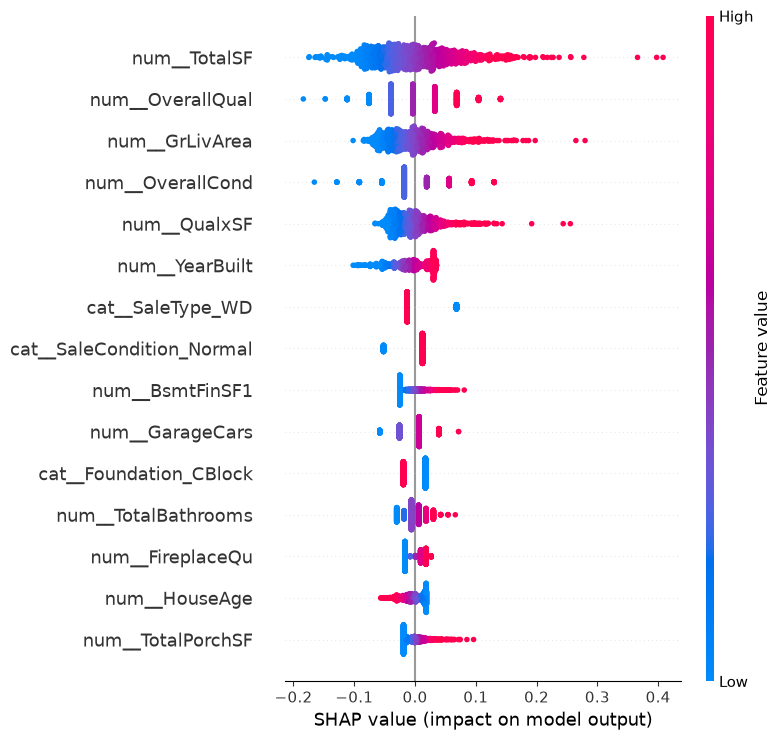

In [78]:
import shap

explainer = shap.Explainer(inner, Xt, feature_names=feat_names)   #inner= fitted model (log price), Xt= preprocesssed training data
shap_values = explainer(Xt)
# This calculates SHAP explanations for the rows in Xt.
# Conceptually, each SHAP value answers:
# For this particular house, how much did this feature push the prediction above or below the baseline?

shap.summary_plot(shap_values, max_display=15)

this graph shows how the feature value affect the final price using SHAP.

in coeffiecient based price drivers there are lot of dummys that got their coefficient increased because of low number of record or coefficient got lowered due to shared credits. so we cant come to a proper conclusion only based on that values 
after using shap we can see lot of dummy features got eliminated from the top drivers list.

Top Price drivers -
- TotalSF
- OverallQual
- GrLivArea
- OverallCond
- QualxSF
- YearBuilt
- SaleType_WD
- SaleCondition_Normal
- BsmtFinSF1
- GarageCars

#### Dependance plot 
- since its  linear model it cant curve.

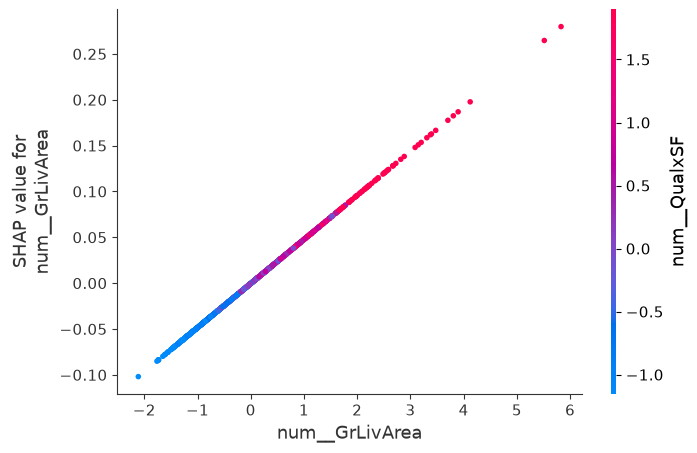

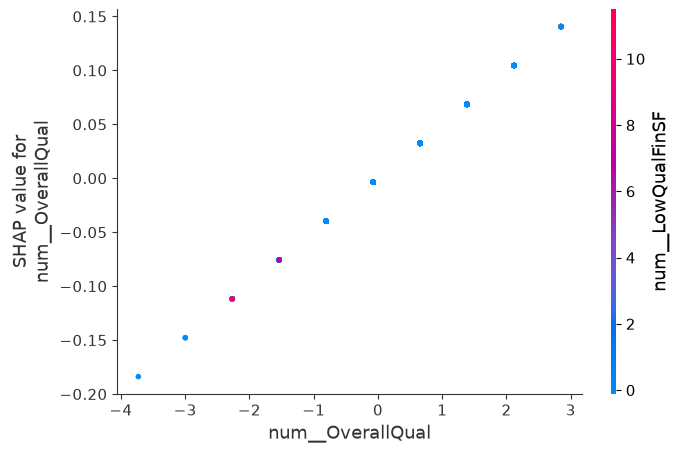

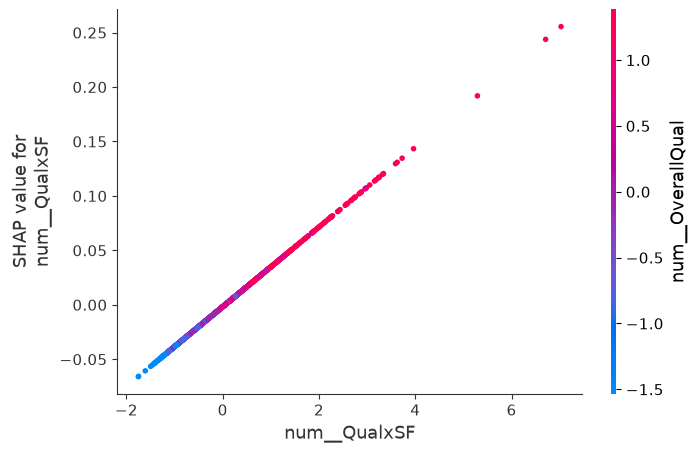

In [79]:
for feat in ["num__GrLivArea", "num__OverallQual", "num__QualxSF"]:
    shap.dependence_plot(feat, shap_values.values, Xt, feature_names=feat_names)

X axis consist of std deviations for that feature

graph 1: QualxSF = quality × area, so big houses automatically carry big QualxSF values.
far-right dots are the biggest homes voting "~+15–20%," the far-left small homes voting "−5–10%.

Graph 2: The far-left dot (x ≈ −3.7) is the single grade-1 house — its quality votes "−18%." The far-right (x ≈ +2.8) is a grade-10 house voting "+16%."
one grade ≈ 0.72 SD, rise per grade ≈ +3.7% — exactly the corrected per-grade number
same as we calculated.

Graph 3: houses that are both big and high-quality get an extra push beyond what size and quality each contribute separately 

#### How does the bathroom affect the price of the house

In [80]:
bath = coefs[coefs.index.str.contains("Bath")]
print(pd.DataFrame({"coef": bath.round(4),
                    "% effect": (np.expm1(bath) * 100).round(1)}))

                       coef  % effect
num__BsmtFullBath    0.0000       0.0
num__BsmtHalfBath   -0.0009      -0.1
num__FullBath        0.0019       0.2
num__HalfBath        0.0116       1.2
num__TotalBathrooms  0.0185       1.9


Among the Bathroom related features our engineered feature TotalBathRooms + 1.9% had the largest coefficient following HalfBath +1.2% per standard deviation increase.

feature overlap with each others so their individual coefficients should be taken as conditional contribution rather than independant estimate.

### TASK 2b - REPORT

#### Method:-
    The selected production model is a tuned ElasticNet regression model train to predict log1p(SalePrice). Of the 253 transformed features, 135 have nonzero coefficients.

    Two complimentry methods were used to interpret the model
1. Standardized coefficients -
       It describes each features contribution to the models prediction, holding other features constant.
       Numeric coefficient represents a one-standard deviation increase in original feature.For a coefficient (c) the corresponding multiplicative change on the model's log-price scale is approximately ((e^c-1) * 100%).
       Categorical coefficient requires care because their interpretation depends on one-hot encoding and refrence category setup

2. SHAP values -
    Explain how individual feature contributes to prediction for individualhouses relative to a baseline. SHAP explanations were computed using a background sample of 100 training houses.
    Global feature importance is commonly ranked by mean absolute SHAP value, which measures the average magnitude of a features contribution across the evaluteed houses. 
       

#### What drives the House price -
    This ranking tells us which features have the largest average influence on the models prediction. 

##### Top 10 features

| Rank | Feature | Mean SHAP value | Direction | Simple interpretation |
|---:|:---|---|---|---|
| 1 | TotalSF | 0.05664 | Higher value = price up,lower value = price down|Total floor area is the strongest feature in the ranking. larger houses tend to receive higher predicted prices|
| 2 | OverallQual | 0.039145 | Higher quality = price up, lower quality = price down |Overall quality is a major price driver. Better construction and finish quality tend to increase predicted prices |
| 3 | GrLivArea | 0.03702 | higher value = price up, lower value = price down | Above-ground living area strongly influences price. More above-ground living space generally increases predicted price |
| 4 | OverallCond | 0.03213 | Higher vaaue = price up, lower value = price down | Overall condition contribute substantially to predictions even though it showed a weak correlation with price in EDA |
| 5 | QualxSF | 0.02778 |Higher value = price up, lower value = price down | Quality * Size shows a stronger signal than each individually. |
| 6 | YearBuilt | 0.02497 |Higher value = price down, lower value = price up | Year built matters. Newer houses generally receives higher predictions when other features are equal|
| 7 | SaleType_WD | 0.02008 | Since its one hot feature we hve to refereance its other categorys too| Sale Type  warrenty deed contribute to the prediction but we cant clearly define the premium for this category|
| 8 | SaleCondition_Normal | 0.01900 | Normal-Sale observation tend to have a small positive contribution, non-normal observation include negative contributions. | Normal ssale condition helps model distinguish ordinary transaction from other sale conditions |
| 9 | BsmtFinSF1 | 0.01890 | Higher value = price up, lower value = price down | Finidhed basement area contributes positively when this feature is high |
| 10 | GarageCars | 0.01820 | Higher capacity = price up, lower capacity = price down   | Garage Capacity matters, with more cars generally associated with higher prediction|

The SHAP analysis identifies total floor area as the strongest influence on the ElasticNet model's predictions, followed by overall quality and above-ground living area. The engineered quality–size interaction also ranks highly, indicating that representing their combined signal adds predictive information. Overall condition, construction year, finished basement area, and garage capacity provide additional useful signals. Newer construction, larger living areas, and higher quality generally push predictions upward, while older house age generally pushes them downward. Sale-related categories also contribute, but their effects should be interpreted cautiously because category frequencies and correlated features can affect individual estimates. These results explain the model's predictions rather than establish causal effects on actual house prices.

OverallCond rank low in EDA But higher in SHAP - because of data shape most high condition ratings are clustured in chheap, older, well-maintianed homes thats what lowered the correlation to -0.08 in EDA  Once the model holds age and location fixed .conditions genuine positive effect emerges.

ExterQual and OverallCond are mirror images — ExterQual strong marginally, ~zero conditionally; OverallCond ~zero marginally, strong conditionally. Marginal association and conditional contribution are different

#### Price effects 

1. Each OverallQual grade ≈ +3.7% - A one-grade increase in overall quality is associated with a higher predicted price.
2. +1 SD of TotalSF ≈ +7.5% - A house with total area one standard deviation higher receives a higher predicted price, holding the model's other features fixed.
3. OverallQual +5.1% per SD - Overall quality carries much of the signal within the quality family.
4. QualxSF +3.7% per SD - The quality–size interaction adds predictive information.
5. TotalBathrooms +1.9% per SD - The engineered total-bathroom feature contributes more strongly than the individual bathroom components in the coefficient table.
6. Neighborhood premiums - The model assigns different predictions to houses in different neighborhoods, all else represented by the model being equal.

#### Why coefficient alone misleads-
Coefficient magnitude only answers "what the per unit effect" - not "what matters."

After comparing this values with our EDA data we can see a lot of things mismatch.
the top price drivers in this table consist of rare records like MSZoning_C (all)
only 10 records. it show meaningless confidence.
HasPool and Poolarea have contradictory coefficient which cancels each others.
Our EDA top price driver feature Overall quality is not present in this table 
(since overall quality credit is split in correlated family members(features))

#### Model vs EDA -
    EDA examines the relationship between a feature and sale price largely on its own. SHAP examines how the fitted model uses that feature when making predictions based on multiple features.
    
    The EDA and SHAP analyses show consistent patterns for overall quality, neighborhood, and above-ground living area. Overall quality had a high η² of 0.67, neighborhood had an η² of 0.57, and GrLivArea had a Pearson correlation of 0.71 with sale price. The fitted model also ranks OverallQual second and GrLivArea third in mean absolute SHAP importance, while neighborhood indicators contribute to its predictions. This agreement is reassuring, although both analyses use the same dataset and therefore do not constitute fully independent validation.
    
    One notable divergence is ExterQual, which showed a strong marginal association with sale price in EDA but had a coefficient close to zero in the fitted model. A plausible explanation is that exterior quality overlaps with OverallQual and other related features. Once the model accounts for those features, ExterQual may add little unique predictive information. A similar effect occurs with GarageArea and GarageCars, which have a correlation of approximately 0.88. These examples illustrate why a feature's individual association with price can differ from its conditional contribution in a multivariable model.

#### Dependance plot 
- since its  linear model it cant curve.

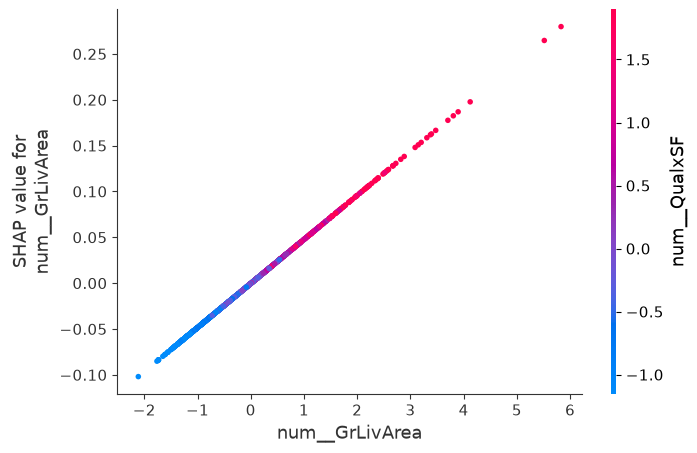

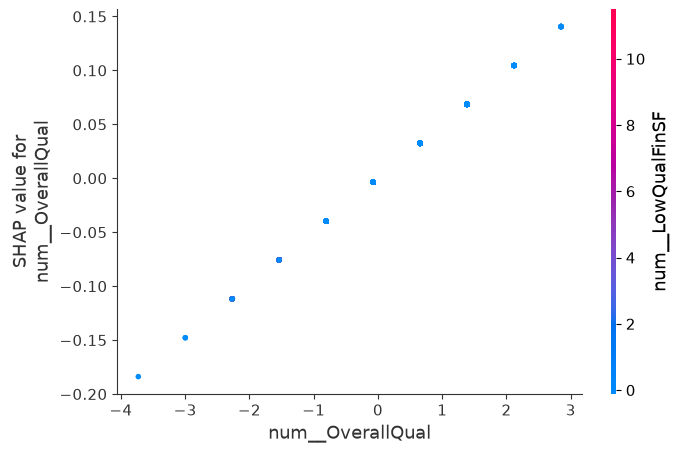

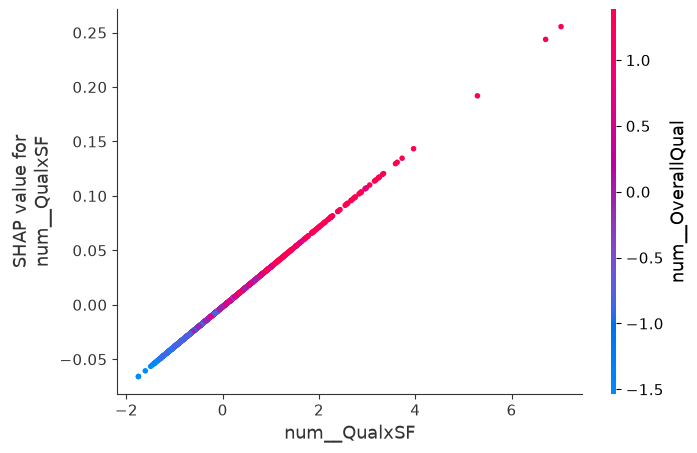

In [81]:
for feat in ["num__GrLivArea", "num__OverallQual", "num__QualxSF"]:
    shap.dependence_plot(feat, shap_values.values, Xt, feature_names=feat_names)

X axis consist of std deviations for that feature

graph 1: QualxSF = quality × area, so big houses automatically carry big QualxSF values.
far-right dots are the biggest homes voting "~+15–20%," the far-left small homes voting "−5–10%.

Graph 2: The far-left dot (x ≈ −3.7) is the single grade-1 house — its quality votes "−18%." The far-right (x ≈ +2.8) is a grade-10 house voting "+16%."
one grade ≈ 0.72 SD, rise per grade ≈ +3.7% — exactly the corrected per-grade number
same as we calculated.

Graph 3: houses that are both big and high-quality get an extra push beyond what size and quality each contribute separately 

### Beeswarm Plot -

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18732\1859656706.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, max_display=15)


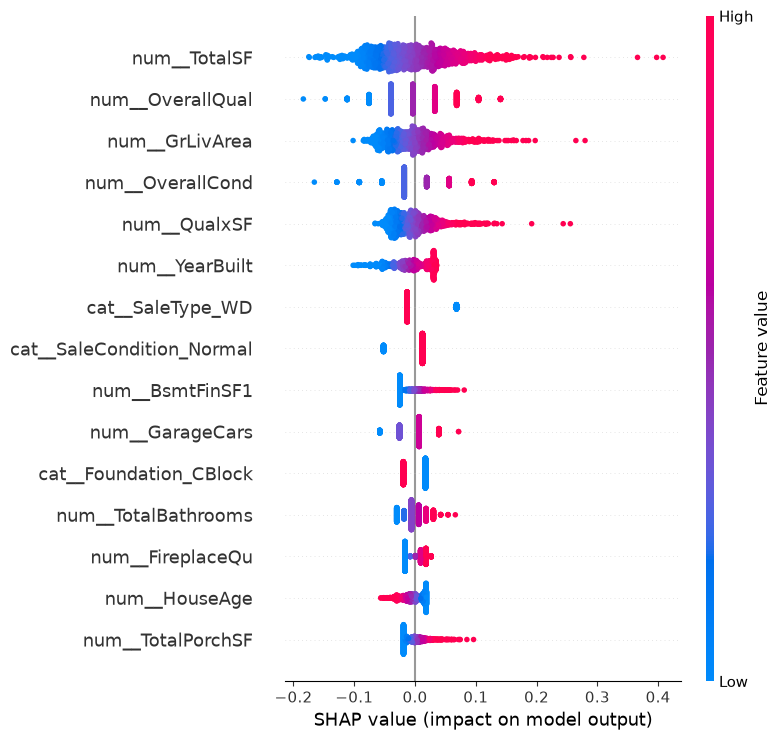

In [82]:
shap.summary_plot(shap_values, max_display=15)

    A SHAP beeswarm plot is a graph that shows which features influence your house-price model's predictions, how strongly they influence them, and whether they push predicted prices up or down.

### Caveats and Limitations

The findings from this analysis should be interpreted with three important limitations in mind.

1. Association is not causation. - EDA and SHAP identify relationships between house features and predicted sale prices. Model coefficients describe associations conditional on the other features included in the model. They do not prove that changing a feature will cause a particular change in a house's market price.

2. Correlated features share predictive information. - Features such as GarageArea and GarageCars, or TotalSF and GrLivArea, capture overlapping information. As a result, the model may distribute predictive influence across related features. A small coefficient does not necessarily mean that a feature is unimportant in isolation.

3. Rare categories require caution. - Coefficients for categories represented by few training examples may be unstable and sensitive to individual observations. Neighborhood and other categorical effects should therefore be reported alongside training-set counts and interpreted as model estimates rather than guaranteed price premiums.

Overall, the model provides useful insights into the patterns associated with house prices in this dataset, but its explanations should be treated as predictive evidence rather than causal or universal conclusions.

## 5. Task 3 : Buyer Recommendations

#### Price per sqft by Neighborhood
    A value neighborhood = low $/sqft AND decent median quality AND enough houses to trust the number

In [83]:
ppsf = df.assign(ppsf=df["SalePrice"] / df["GrLivArea"])     # $ value per house per sqft

value_map = ppsf.groupby("Neighborhood").agg(
    houses=("SalePrice", "size"),
    median_price=("SalePrice", "median"),
    median_ppsf=("ppsf", "median"),
    median_quality=("OverallQual", "median"),
).sort_values("median_ppsf")

value_map_reliable = value_map.loc[value_map["houses"] >= 20]
print(value_map_reliable.round(1))

              houses  median_price  median_ppsf  median_quality
Neighborhood                                                   
SWISU             25      139500.0         80.6             6.0
IDOTRR            37      103000.0         90.6             5.0
OldTown          113      119000.0         92.1             5.0
BrkSide           58      124300.0        100.9             5.0
Edwards           98      119500.0        101.0             5.0
NWAmes            73      182900.0        110.9             6.0
Crawfor           51      200624.0        115.5             6.0
SawyerW           59      179900.0        116.8             6.0
Gilbert           79      181000.0        117.5             7.0
ClearCr           28      200250.0        119.3             6.0
NAmes            225      140000.0        120.4             5.0
Sawyer            74      135000.0        120.8             5.0
NoRidge           41      301500.0        128.2             8.0
Mitchel           49      153500.0      

Median sale price alone can confuse house size with location. To make a more useful buyer-facing comparison, I calculated each house's sale price per square foot of above-ground living area (GrLivArea) and compared neighborhoods using the median of this ratio. The table also reports the number of houses and median overall quality, allowing lower-cost neighborhoods to be considered alongside typical house quality and sample size.

For neighborhood comparisons, I retained only areas with at least 20 observations. This threshold reduces reliance on very small groups but does not guarantee statistical reliability.

This table provides a marginal market view: the prices and price-per-square-foot values observed in each neighborhood without controlling for other property characteristics. By contrast, the ElasticNet neighborhood coefficients provide a conditional model view, estimating each indicator's contribution while accounting for the other included features. The two perspectives answer different questions and should not be interpreted as interchangeable measures of a neighborhood premium.

#### Suggestion according to budget : area * price * requirements

In [84]:
def value_picks(lo, hi, min_houses=20):
    seg = ppsf[(ppsf["SalePrice"] >= lo) & (ppsf["SalePrice"] < hi)]
    t = seg.groupby("Neighborhood").agg(
        houses=("SalePrice", "size"),
        median_ppsf=("ppsf", "median"),
        median_quality=("OverallQual", "median"),
    )
    return t[t["houses"] >= min_houses].sort_values("median_ppsf").head(3)

print("Under $150K:");        print(value_picks(0, 150_000))
print("$150K–$250K:");        print(value_picks(150_000, 250_000))
print("$250K and above:");    print(value_picks(250_000, 10**9))

Under $150K:
              houses  median_ppsf  median_quality
Neighborhood                                     
OldTown           92    85.961576             5.0
IDOTRR            35    89.047195             5.0
Edwards           80    94.393973             5.0
$150K–$250K:
              houses  median_ppsf  median_quality
Neighborhood                                     
Gilbert           73   114.314790             7.0
NWAmes            59   114.644107             6.0
Crawfor           29   115.338794             6.0
$250K and above:
              houses  median_ppsf  median_quality
Neighborhood                                     
NoRidge           37   128.637060             8.0
Somerst           27   155.867971             8.0
NridgHt           59   170.177100             9.0


I compared neighborhoods using three measures: median sale price, median price per square foot of above-ground living area, and median overall house quality. To avoid drawing conclusions from very small groups, I included only neighborhoods with at least 20 houses in the overall comparison and at least 20 houses within each budget range.

Key findings:

- Overall comparison: SWISU has the lowest median price per square foot (USD 80.60), followed by IDOTRR (USD 90.60) and OldTown (USD 92.10). However, these neighborhoods have different median quality levels, so the lowest price per square foot does not automatically mean the best overall value.
- Under 150,000 USD: OldTown has the lowest median price per square foot (USD85.96), followed by IDOTRR (USD 89.05) and Edwards (USD 94.39). All three have a median overall quality score of 5.
- 150,000–250,000 USD: Gilbert offers the lowest median price per square foot (USD 114.31) among the qualifying neighborhoods, with a median quality score of 7. NWAmes and Crawfor follow, with median quality scores of 6.
- 250,000 USD and above: NoRidge has the lowest median price per square foot ($128.64) among the qualifying neighborhoods, with a median quality score of 8. Somerst and NridgHt have higher median prices per square foot and median quality scores of 8 and 9, respectively.

Important interpretation: The overall table includes all houses in each neighborhood, whereas the budget-specific tables include only houses within the specified price range. Therefore, a neighborhood can qualify for the overall table but disappear from a budget-specific table if fewer than 20 of its houses fall within that price range. For example, SWISU qualifies overall but does not appear in the under-$150,000 results because it has fewer than 20 houses in that price range.

Conclusion: The results identify potential value candidates within each budget, but price per square foot and median quality are only screening measures. They do not control for all differences in house size, age, condition, or other characteristics, so these comparisons should be treated as descriptive rather than proof that one neighborhood provides better value than another.

#### Things to Prioritize vs Not to pay for

| Priority | Evidence | Interpretation |
|---|---|---|
| 1. Total space | +7.5% per SD of TotalSF | pay for space you'll use — strongest lever in the data |
| 2. Overall quality | +3.7% per grade | the quality staircase is real; a grade up is worth thousands |
| 3. Quality × size together | QualxSF +3.7%/SD | quality is worth *more* in bigger houses — the two compound |
| 4. Bathrooms | TotalBathrooms +1.9%/SD | total bathing capacity matters, not the configuration |
| 5. Condition (given age) | OverallCond conditional effect | once age is accounted for, better condition genuinely prices higher |



##### Dont pay a premium for

| Feature | Evidence | Interpretation |
|---|---|---|
| A pool | HasPool −5.9% and PoolArea +6.1% cancel; 7 pools in 1,458 houses | the market cannot even measure a pool premium here — don't pay for one as an "investment" |
| Extra kitchens | KitchenAbvGr: weak negative, duplex/low-end proxy | 2+ kitchens signals low-end property type, not value |
| Enclosed porch "bonus space" | weak negative, old-house proxy | it's an age signal in disguise, not a feature |

##### Renovatable vs. fixed:

| Fixed (choose at purchase) | Renovatable (can add later) |
|---|---|
| Neighborhood, lot, YearBuilt, foundation, zoning, size *footprint* | Overall condition, total bathrooms, finish quality (via comprehensive renovation) |

##### Note:
    Broad property quality is a stronger predictive signal than kitchen quality considered separately in this model.
    
    This supports evaluating the property's overall condition and quality rather than assuming that a single component upgrade will command a predictable price premium. However, this is an association in the fitted model, not proof that kitchen upgrades have no value or that comprehensive renovations will necessarily deliver a better return

## TASK 3 Buyer Recommendation REPORT

#### Who this guide is for

this guide is for buyers comparing homes in Ames, Iowa, using approximately 1,458 historical home sales from 2006–2010. It examines neighborhood prices, price per square foot, overall house quality, and model-based price patterns to help buyers identify areas worth investigating at different budgets.

The price estimates are useful starting points, not promises. In testing, the selected model had a mean absolute error (MAE) of approximately 14,106 USD. In plain language, its predictions differed from actual sale prices by about 14,000 USD on average in the held-out test sample. Individual errors can be much larger or smaller.

#### The Value Map: Where to look

The neighborhood comparison considers the number of sales, median sale price, median price per square foot of above-ground living area, and median overall quality. To make comparisons more reliable, the main table includes only neighborhoods with at least 20 recorded sales.

In [85]:
print(value_map_reliable.round(1))

              houses  median_price  median_ppsf  median_quality
Neighborhood                                                   
SWISU             25      139500.0         80.6             6.0
IDOTRR            37      103000.0         90.6             5.0
OldTown          113      119000.0         92.1             5.0
BrkSide           58      124300.0        100.9             5.0
Edwards           98      119500.0        101.0             5.0
NWAmes            73      182900.0        110.9             6.0
Crawfor           51      200624.0        115.5             6.0
SawyerW           59      179900.0        116.8             6.0
Gilbert           79      181000.0        117.5             7.0
ClearCr           28      200250.0        119.3             6.0
NAmes            225      140000.0        120.4             5.0
Sawyer            74      135000.0        120.8             5.0
NoRidge           41      301500.0        128.2             8.0
Mitchel           49      153500.0      

##### Potential value candidates

SWISU: Lowest median price per square foot among the neighborhoods meeting the sample-size rule, at approximately 80.60 USD. Its median sale price was 139,500 USD and median overall quality was 6.

IDOTRR: Median price per square foot of approximately 90.60 USD, median sale price of 103,000 USD and median overall quality of 5.

OldTown: Median price per square foot of approximately 92.10 USD, median sale price of 119,000USD and median overall quality of 5.

These neighborhoods are worth investigating for buyers prioritizing lower prices per square foot. However, a lower figure does not automatically mean a better deal: house size, age, condition, layout, and renovation needs can differ.

##### Potential premium neighborhoods

NridgHt: Median sale price of approximately 315,000 USD, median price per square foot of $158.00, and median overall quality of 8.

StoneBr: Median sale price of approximately 278,000 USD, median price per square foot of 157.90 USD, and median overall quality of 8.

NoRidge: Median sale price of approximately 301,500 USD, median price per square foot of 128.20 USD, and median overall quality of 8.

These neighborhoods had relatively high median prices or quality scores. NoRidge is particularly interesting because its median sale price was high while its median price per square foot was lower than those of NridgHt and StoneBr.

**Note**- The 20-sale rule reduces the risk of drawing conclusions from very small samples, but it does not guarantee that a neighborhood's figures are representative of every home there.

#### Three Budget Profiles -

The following profiles use homes within each price range. A neighborhood is included only if it has at least 20 sales within that particular range.

**Budget A: Under 150,000 USD**

OldTown — lowest median price per square foot among the qualifying neighborhoods. Its median was approximately 85.96 USD per square foot, with a median overall quality score of 5.

IDOTRR — another lower-cost option. Its median was approximately 89.05 USD per square foot, also with a median quality score of 5.

Edwards — an additional neighborhood to compare. Its median was approximately $94.39 per square foot, with a median quality score of 5.

Buyer takeaway: Compare the actual condition and renovation costs of homes in these areas. The low purchase price may be attractive, but inspection findings and likely repair expenses matter.

**Budget B: 150,000 USD–250,000 USD**

Gilbert — strongest combination among these three on the reported measures. It had the lowest median price per square foot of approximately 114.31 USD and a median quality score of 7.

NWAmes — a lower-price-per-square-foot alternative. Its median was approximately 114.64 USD per square foot, with a median quality score of 6.

Crawfor — another option worth investigating. Its median was approximately 115.34 USD per square foot, with a median quality score of 6.

Buyer takeaway: Gilbert is a useful starting point if you want to compare relatively high reported quality with a lower median price per square foot. Still, compare similar-sized homes and inspect each property's condition before deciding.

**Budget C: 250,000 USD and Above**

NoRidge — the lowest median price per square foot among the qualifying neighborhoods. Its median was approximately USD 128.64 per square foot, with a median quality score of 8.

Somerst — a higher-price-per-square-foot alternative. Its median was approximately USD 155.87 per square foot, with a median quality score of 8.

NridgHt — the highest reported median quality among these three. Its median was approximately USD 170.18 per square foot, with a median quality score of 9.

Buyer takeaway: NoRidge is worth comparing first if price per square foot matters. Somerst and NridgHt may also appeal to buyers seeking homes with higher reported quality, but the figures alone cannot establish why buyers paid more.

Important: These are screening candidates, not definitive rankings of the best neighborhoods. Price per square foot is based on above-ground living area and does not adjust for every difference between properties.

#### 4. What to Prioritize — and What Not to Pay Extra For

##### What to prioritize

| Priority | What the data suggests | Advice for buyers |
|---|---|---|
| 1. Living space | Larger homes tend to sell for more. | Pay for space you will actually use, not just a bigger number on the listing. |
| 2. Overall quality | Homes with higher overall quality tend to sell for more. | Look at the quality of the whole house, not just one upgraded room. |
| 3. Quality and size together | Size and quality work together to influence price. | Compare homes of similar size and quality when judging whether a price is reasonable. |
| 4. Bathrooms | Total bathroom capacity is useful for predicting price. | Choose a bathroom layout that suits your household rather than paying extra for a particular configuration. |
| 5. Overall condition | Better-condition homes tend to have higher predicted prices, even after accounting for age. | Check maintenance and repair needs carefully, even in older homes. |

##### What not to pay extra for automatically

| Feature | What the data suggests | Advice for buyers |
|---|---|---|
| Swimming pool | Too few homes had pools to estimate their value reliably. | Buy a pool for your enjoyment, not because you expect it to pay for itself at resale. |
| Extra kitchens | More kitchens did not show a clear price advantage in this dataset. | Consider whether they suit the property's layout and your needs. |
| Enclosed porch | The feature did not show a clear independent price advantage. | Check its condition and usefulness before paying extra for it. |

These results do not mean that these features have no value. Their value depends on the property, buyer preferences, maintenance costs, and local demand.

##### What to choose carefully and what you can improve later

Choose carefully when buying: location, neighborhood, lot, foundation, house age, and basic size. These can be difficult or expensive to change.

Consider improving later: maintenance, finishes, bathroom capacity, and some interior spaces. Before renovating, compare the likely cost with the benefit you expect.

##### What about kitchen upgrades?

The model found that overall house quality was a stronger price signal than kitchen quality considered separately. This does not mean kitchen upgrades are worthless. It means the data does not establish a reliable extra price premium for a kitchen upgrade on its own.

Practical advice: Focus on the condition and quality of the whole property. Do not assume that one expensive upgrade will automatically increase resale value by the same amount.

##### Bottom line

Prioritize useful space, overall quality, good condition, and a layout that suits your needs. Avoid paying extra for individual features just because they sound attractive. Use these findings to narrow your choices, then inspect the actual property and compare similar homes before making an offer.

#### Caveats Buyers Should Understand

- Historical market: These results describe Ames sales from 2006–2010. They should not be treated as current market prices or used directly to value a home today.

- Predictions are estimates: The approximately $14,106 MAE is an average absolute error in the test sample, not a guaranteed maximum error or a fixed uncertainty range for every property.

- Associations are not guarantees: Features associated with higher prices do not necessarily cause those prices. The model cannot prove that an upgrade or neighborhood choice will deliver a particular return.

- Neighborhood medians hide variation: A neighborhood can contain both excellent and poor-value properties. Median figures describe the middle of the observed sales, not every home.

- Small samples remain uncertain: Requiring at least 20 sales helps avoid extremely small groups, but results can still change with the sample and market conditions.

- Inspect the individual house: A neighborhood that looks attractive in the data does not guarantee that a particular property is sound. Check structural condition, roof, foundation, systems, water issues, required repairs, and comparable recent sales before making an offer.

#### Final Recommendation

Use this guide to narrow the search, not to make the final purchase decision. Start with neighborhoods and price ranges that fit your budget, compare homes of similar size and condition, and investigate the reasons behind any unusually low price per square foot. The best purchase is not necessarily the cheapest neighborhood or the highest-quality home; it is the property whose price, condition, features, and repair needs make sense for your circumstances.

## The Deployment Model

##### training the model on full data and storing it

In [86]:
from sklearn.base import clone
import joblib

production_model = clone(enet_search.best_estimator_)
production_model.fit(X, y)          # X, y = the FULL dataset (pre-split variables, 1,458 rows)

joblib.dump(production_model, "../models/house_price_elasticnet.joblib")

# smoke test — load it back, predict, confirm dollars
loaded = joblib.load("../models/house_price_elasticnet.joblib")
print(loaded.predict(X.head(3)).round(0))

[204425. 194833. 211371.]


after the refit, there are no more honest performance numbers to compute on this data — everything is training data now. The holdout figures (0.1081, $14.1K MAE) remain the performance claim, permanently.

## Metadata

In [87]:
import json, sklearn
from datetime import date

metadata = {
    "model": "Tuned ElasticNet in sklearn Pipeline (log1p target)",
    "best_params": {k: float(v) for k, v in enet_search.best_params_.items()},
    "cv_log_rmse_5fold": 0.1146,
    "holdout_log_rmse": 0.1081,
    "holdout_mae_usd": 14106,
    "holdout_mape_pct": 8.0,
    "training_rows": int(len(df)),
    "seed": 42,
    "versions": {"sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
    "trained_on": "ALL rows (train + holdout) — deployment refit",
    "date": str(date.today()),
}
with open("../models/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

## Requirements

In [88]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.


### MODEL COMPARISON REPORT

#### the full results table

| Model | CV log-RMSE | in-sample | gap | What it tells us|
|---|---:|---:|---:|---|
| ElasticNet (α=0.0002, L1_ratio=0.94) | 0.1146 ±0.0109 | 0.0955 | 0.0191 | best score - but its similar to lasso with just alittle of L2 penalty |
| Lasso (α=0.0002) | 0.1149 ±0.0109 | 0.0950 | 0.0199 | kept 141/253 features -the deleted 112 features were redundant |
| Ridge (α=8.47) | 0.1156 ±0.0123 | 0.0962 | 0.0194 | the stability is restored and std is halved as compared to linear regression |
| XGBoost | 0.1160 ±0.0109 | 0.0681 | 0.0479 | the score is much closer to linear family models . the tuning boundary extension gained 0.0009 = noise|
| LightGBM | 0.1209 ±0.0105 | 0.0373 | 0.0836 | the models leaf-wise growth overfitted the 1166 rows |
| RandomForest | 0.1319 ±0.0116 | 0.0518 | 0.0801 | it underperform compared to linear models increase complexity brought nothing |
| LinearRegression | 0.1435 ± 0.0203 | - | - | The model shows 87% of variance but the std in different folds is bigger showing unpenalized collinearity instability |
| Dummy (median) | 0.3979 ± 0.0134 | - | - | we use this as a baseline to compare other result it is the  R² denominator |


### Final Model choice

The top 4 models are within 0.0014 of each other on fold std of 0.01 - a statistical tie.

Regularized linear models outperformed the non-linear model since feature engineering did the non-linear work in advance.

| Criterion | ElasticNet | XGBoost |
|:---|:---|:---|
| CV Score | 0.1146 | 0.1160  - a tie because difference of 0.0014 is lower than fold- std of ~0.011|
| Fold stability | ±0.0109 | ±0.0109 |
| Single - fit time | 0.27s | 5.77s | 
| Interpretability | 141 features + their coefficients make it easier to explain to a buyer | requires SHAP |
| Simplicity | one penalized formula | ensembele of 1600 trees |


- The difference of 0.0014 is small compared with the fold standard deviation of 0.0109.
  the mean scores alone do not establish a meaningful winner.
- Since predictive performance is close, the decision shifts to deployment criteria: interpretability, complexity, training time, and maintainability.
- ElasticNet Edges out massivly on training time, interpretability and model complexity as shown in above table.
- I would select ElasticNet because it achieves the lowest mean CV Log-RMSE (0.1146) while offering a simpler, more explainable model than XGBoost.


ElasticNet was selected as the final model because it achieved the lowest cross-validation Log-RMSE (0.1146) among the evaluated models while remaining relatively simple, fast, and interpretable.

On the untouched holdout dataset, the model achieved:

Holdout Log-RMSE: 0.1081

Holdout MAE: $14,106

Holdout MAPE: 8.0%
MAPE can make a model look relatively worse on cheaper houses and relatively better on expensive houses. More precisely, it weights errors relative to price rather than giving every dollar of error equal importance.

Interpretation: On average, the model's absolute prediction error was approximately $14,106 per house. Its MAPE of 8.0% means that the average absolute prediction error, expressed relative to each house's actual sale price, was 8%.


##### Holdout (0.1081) came in slightly better than the CV estimate (0.1146), within expected single-split variance — the one-time evaluation confirms the CV story, with no leakage pathway since selection never touched the holdout."

## Challenges log - PRCP-1020 House Price Prediction

| Theme | Entries |
|---|---|
| Data loading & types | 1, 3, 7, 16 |
| Missingness semantics | 2, 4, 5, 6, 8, 14, 15 |
| EDA traps | 9, 10, 11, 12, 13 |
| Modeling & interpretation | 17, 18, 19 |



#===========================================================
Entry 1: pandas default loading erases the category/missing distinction

problem: 

the dataset uses text as (NA/None) to mean the house does not have this feature
a default pd.read_csv convert this values as NaN
making house having no pool indestinguishable from "value unknown" 
if we impute that column some houses which doesnt have a pool will show that they have it making data corrupt.

Tried: pd.read_csv(..., keep_default_na=False, na_values=[""])

Why: keep_default_na=False  disables the function so "NA/None" load as ordinary categories
na_values=[""] keeps genuinely empty cells as NaN so true missingness stays countable

Result: Distinction preserved. Verified: MasVnrType shows "None" (864) as acategory; Alley shows "NA" (1369) as a category.

#===============================================================

Entry 2 - the provided file stored ALL blanks as "NA" strings

problem: df.isna().sum() showed 0 missing values
feature absence and value missing was hard to diffrentiate
3 column were misclassified as str data type due to presence of "NA"

Tried: Data type audit - compared all 81 columns against their documentated types 
dignosed each broken column against related features to get their values understanding before making any changes
(GarageYrBlt "NA" rows vsGarageType; MasVnrArea "NA" rows vs MasVnrType; LotFrontage "NA" rows vsNeighborhood). Only then repaired with pd.to_numeric(errors="coerce").

why: "NA" means different things per column : absence or genuine missing. Repairing without diagnosinsing would have mixed the meanings

Result: 38 numeric columns verfied = 35 int64 + 3 float64
True Nan VISIBLE =LotFrontage 259, GarageYrBlt 81 (absence),MasVnrArea 8.

#==============================================================

Entry 3 - documentation vs file column name mismatch 

problem: Spec says "Bedroom" and "Kitchen"; file says "BedroomAbvGr" and"KitchenAbvGr". File also has an "Id" column absent from the documented list.

tried: Cross-checked documented names against df.columns.

Why: can cause wrong featureselection later

Result: 3 differences found; other 78 names match. Noted in audit findings;all code uses actual file names.

#==============================================================

Entry 4 - two houses where "NA" is genuine missing not absent in basement related column
ALL 19 columns missing value and nonexistant value classified with reasoning all table data is clear


problem: the five basement column should agree but the count were 37/37/38/38/38
BsmtExposure and BsmtFinType2 eachcarried one extra "NA".

Tried: took no basement as TotalBsmtSF == 0
and then searched for mismatch betweeen each column and does the basement exist or not

why: "NA" in this dataset can be missing value or nonexistant value
since basement area has a value we cant treat corresponding basement attribute as non existant it must have a value

result: id 949 and id 333 both classified as genuine missing and need to be imputed

ALL 19 columns missing value and nonexistant value classified with reasoning all table data is clear

#========================================================

Entry 5: MasVnrType hold both a valid category and genuine missing

problem - "None"(864)- documented value has meaning 
           and "NA"(8)- is not documented genuine missing
           both live in same column and need different handling

outcome: "None" kept as is
        "NA " is classified genuine missing

#========================================================

Entry 6 : "NA" HAS DIFFERENT MEANING IN DIFFERENT COLUMNS
        (genuine missing, absense, validcategory)

problem:   categorizing the meaning of NA and deciding the action on it


tried:   using logic and cross comparing
FireplaceQu  = all 690 FireplaceQu "NA" houses have Fireplaces = 0
GarageType  = all 81 GarageType "NA" houses have GarageCars = 0 and GarageArea = 0
BsmtQual  = all 37 BsmtQual "NA" houses have TotalBsmtSF = 0
reverse: all 7 PoolArea > 0 houses carry a PoolQC rating; zero houseswith fireplaces lack FireplaceQu

Outcome: 
    (19 columns; other 62 completely clean)
    decided which value need which type of fill
     Stated limitation: Alley, Fence, MiscFeaturehave no numeric companion column — trusted on documentation alone.

#==========================================================

Entry 7: GarageYrBlt : absence inside a year column

problem:
    81 NaN = houses with no garage. Filling 0 creates a meaningless"year 0" that breaks any age-based feature.

solution:
    Fill with YearBuilt + add a HasGarage binary flag.

Reason: putting it as year 0 makes the data inconsistant.

#=============================================================

Entry 8: LotFrontage : 259 genuine missing

problem : missing values without a pattern 
        if tried to impute based on whole data the chances of data leak in training data is high

solution: impute inside the sklearn pipeline.

#============================================================
Entry 9: skewness

Problem: SalePrice is right-skewed(1.88)- the expansive houses dominates squared error

Technique: Model log1p(SalePrice) 

Why: log 1p is zero-safe and it turns percentage relationships additive- the shape most linear model assume

Result: skew 1.88 -> 0.12

#===============================================================
Entry 10: two contradictory houses

Problem: ids 529 and 1299 each value is plausible alone
but jointly absurd, they teach model that hugh area means low price

Technique: Scatterplot + SaleCondition cross-check

Why: Both are partial sales incomplete transactions whose price doesnt reflect completed market value
ids 692 and 1183 are eqaully large but have corresponding larger price

Result: ID 524 AND ID 11299 flagged for removal

#============================================================
Entry 11: yearRemodAdd 1950 clamp

Problem: spike at exactly 1950 

Technique:
treat 1950 as unknown/default not a geniune remodel year

why: "years since remodel" would credit those house with renovation they may never had

Result: Noted for future action

#=========================================================
Entry 12: Raw ANOVA F misled on many-category column

Problem:
F- ranking placed neighbourhood at #12 despite location being a primary driver. it penalize having bigger number of categories

Technique:
Re-ranked with η² 

Why:
η² is category-count-fair; F inflates few-category columns 

Result: Neighborhood 0.57 → #2, OverallQual 0.67 → #1. Also exposed MSSubClass:−0.08 as a number vs η² 0.33 as a category — it must be recast.

#===========================================================
Entry 13:IQR rule degenerates on zero-inflated column

Problem : sweep flagged 208 outliers in EnclosedPorch(and 8 more columns)

Technique: Diagnosed the rule: >75% zeroes -> q1=q3=0
-> iqr=0 every non zero value flagged

Why:
the rule silently break on data shape:
flag counts are feature haverinventories not anomalies

Resutl:
Zero data errors: zero heavy clumn becomes binary flags 
only 524/1299 removed

#==============================================================
Entry 14 — The order of handling missing values matters

Problem: Replacing every "NA" with "None" would have incorrectly treated two houses as having no basement. However, Id 949 has a 936 sqft basement, and Id 333 has BsmtFinSF2 = 479.

Technique: Identified and imputed these two genuine missing values before filling the remaining "NA" values. Used the mode from the correct group: houses with basements for BsmtExposure, and houses with BsmtFinSF2 > 0 for BsmtFinType2.

Why: "NA" can mean either a missing value or an absent feature. Handling it in the wrong order would destroy this distinction.

Result: Both houses were imputed using the correct groups. The remaining "NA" values were safely converted to "None" where they represented feature absence.

#===========================================================================
Entry 15 — Two imputations used the full dataset

Problem: The missing values for Ids 949 and 333 were filled using modes calculated before splitting the data into training and testing sets. This creates a small risk of data leakage.

Why accepted: The correct mode had to come from a specific group of houses. A standard SimpleImputer cannot directly handle these group-specific conditions. Using a general mode could give incorrect results.

Resolution: Accepted this minor limitation because only two values were affected out of approximately 118,000 cells, and the modes were expected to be stable. The Electrical column was handled inside the sklearn pipeline to avoid leakage.

Future improvement: Build a custom group-aware imputer that learns the correct modes from the training data only.

#======================================================================
Entry 16 — Ordinal categories lost their correct data type

Problem: After replacing category labels with numbers, the 20 ordinal columns contained integer values but still had object data types. As a result, pandas incorrectly sent them to the categorical pipeline instead of the numerical pipeline, losing their natural order.

Technique: Used pd.to_numeric() after replacing the labels, with errors="raise" to catch any unmapped values.

Why: Changing the values does not always change the column's data type automatically. Ordinal features must retain their numerical order, such as Ex > Gd > TA > Fa.

Result: All 20 ordinal columns were verified as int64. The pipeline correctly identified 63 numerical and 23 categorical columns before model training.

#=============================================================================
Entry 17 — Linear Regression was unstable across folds

Problem: Plain Linear Regression produced a reasonable average score, but its cross-validation results varied considerably across folds, ranging from 0.119 to 0.170 in log-RMSE.

Why: Several house features were strongly correlated. Even though sklearn kept the coefficients relatively small, the model's predictions were less stable across different training folds.

Technique: Used Ridge Regression, which adds L2 regularization to reduce sensitivity to correlated features. The tuned alpha was 8.47.

Result: The average log-RMSE improved from 0.1435 to 0.1156, and the fold-to-fold standard deviation decreased to 0.0123.

Lesson: A good average score is not enough. Checking variation across folds helps identify unstable models.

#================================================================================
Entry 18 — XGBoost reached its search limits

Problem: The tuned XGBoost model reached the search boundaries for four parameters: n_estimators, learning_rate, subsample, and colsample_bytree. This suggested that a wider search might improve the result.

Technique: Extended the search range once and decided the stopping rule beforehand: stop if the improvement is less than 0.005, half the original fold standard deviation.

Why: Repeatedly expanding the search can waste time chasing tiny improvements caused by noise. A predefined stopping rule keeps the decision objective.

Result: Log-RMSE improved only from 0.1169 to 0.1160, a gain of 0.0009. The new parameters were more extreme, but the improvement remained very small.

Conclusion: XGBoost had reached diminishing returns. The top four models were treated as effectively tied, and the final model choice was based on additional criteria.

#======================================================================================
Entry 19 — An engineered feature duplicated information

Problem: HouseAge was calculated as YrSold - YearBuilt, but both original columns were also kept in the model. This created an exact linear relationship between the three features.

Why: ElasticNet could distribute the effect across these correlated features in different ways. As a result, interpreting the coefficient or SHAP value of one column alone could give a misleading picture.

Resolution: Kept the production model unchanged because the dependency did not affect its predictions in this case. Interpreted the age-related features together rather than drawing conclusions from one coefficient alone.

Why no retraining: The model had already undergone its one-time holdout evaluation. Retraining after seeing those results could compromise the integrity of that evaluation.

Lesson: When creating a feature from existing columns, decide whether to keep the original columns or interpret the related features as a group.

